# Análise de Sentimentos em Dados de Saúde Mental com Técnicas de Text Mining

Mestrado em Business Intelligence and Analytics — Text Mining para Business Analytics

Este notebook apresenta o desenvolvimento completo de um projeto de Text Mining aplicado à **análise de sentimentos**. A estrutura foi organizada para funcionar simultaneamente como implementação em Python e como relatório técnico, cobrindo: caracterização dos dados, pré-processamento, extração/seleção de atributos, classificação supervisionada, comparação de modelos, aplicação a novos exemplos e exploração de uma abordagem baseada em LLM.


## 1. Introdução

A análise de sentimentos é uma área do Text Mining que procura identificar automaticamente a polaridade emocional expressa em texto. Esta tarefa é particularmente relevante em ambientes digitais, onde grandes volumes de comentários, publicações e mensagens são produzidos continuamente e podem conter informação útil para apoio à decisão.

Neste trabalho, o problema é formulado como uma tarefa de **classificação supervisionada**, em que cada texto é associado a uma classe de sentimento. Embora o dataset original contenha três categorias:**positive**, **negative** e **neutral**, optou-se, numa fase posterior, por remover a classe neutra e focar a modelação numa classificação binária entre sentimentos positivos e negativos.

A escolha deste enquadramento permite reduzir a ambiguidade associada aos textos neutros e concentrar a avaliação na distinção entre polaridades opostas. Para isso, foi desenvolvido um pipeline completo que inclui análise exploratória, limpeza e normalização textual, extração de atributos com TF-IDF, seleção de variáveis relevantes, treino de classificadores supervisionados e comparação com uma abordagem baseada em modelo de linguagem pré-treinado.


## 2. Trabalho Relacionado

A análise de sentimentos aplicada à saúde mental em redes sociais tem sido objeto crescente de investigação académica, motivada pelo volume de conteúdo emocional produzido diariamente em plataformas como o Twitter.

Obagbuwa et al. (2023) utilizaram dados de publicações no Twitter para prever indicadores de depressão através de quatro modelos de Machine Learning: XGBoost, Random Forest, Logistic Regression e SVM , com pré-processamento baseado em tokenização, remoção de stopwords e stemming. Os resultados indicaram que a Logistic Regression e o SVM produziram os melhores resultados, com a Logistic Regression a apresentar vantagem adicional em termos de tempo de execução. O presente trabalho diferencia-se por incorporar um pipeline de pré-processamento mais extenso (incluindo NER, expansão de chatwords, emojis e tratamento de negação), por incluir balanceamento de classes com oversampling e por complementar os modelos clássicos com fine-tuning de um modelo Transformer.

Sankar et al. (2024) analisaram tweets em inglês e malaio para deteção de depressão, comparando BoW e TF-IDF como técnicas de extração de features com classificadores SVM, Random Forest, Naive Bayes e LSTM. O SVM com TF-IDF obteve o melhor desempenho, com valores de accuracy, precision e recall na ordem dos 90%. Ao contrário deste estudo, que compara dois métodos de feature extraction, o presente trabalho foca-se na comparação entre múltiplos classificadores com a mesma representação TF-IDF, incluindo adicionalmente a experiência com N-grams e a comparação com um LLM.

Aizawa et al. (2023) analisaram sentimentos em tweets sobre saúde mental e depressão antes e durante a pandemia de COVID-19, combinando análise de sentimentos, topic modeling e classificação com Machine Learning. O classificador BERT obteve o melhor desempenho, com accuracy de 81% para tweets com a hashtag #MentalHealth. Este estudo é relevante por demonstrar a aplicabilidade de modelos Transformer neste domínio, algo que o presente trabalho explora através do fine-tuning do DistilBERT, obtendo resultados competitivos e superiores aos modelos clássicos deste projeto, com accuracy de 90,00% na versão sem pré-processamento.

Um estudo publicado em conferência IEEE (2024) analisou mais de 53.000 publicações rotuladas em redes sociais, aplicando Logistic Regression com TF-IDF e análise de polaridade para classificar condições como Ansiedade, Bipolaridade e estado Normal, atingindo uma accuracy global de 87%. O estudo identificou como principais limitações o desequilíbrio entre classes e a semelhança semântica entre categorias. O presente trabalho aborda diretamente o problema do desequilíbrio de classes através da aplicação de oversampling, optando simultaneamente por uma classificação binária (positivo/negativo) para reduzir a ambiguidade semântica.

Lossio-Ventura et al. (2024) compararam o ChatGPT e modelos Transformer fine-tuned com ferramentas tradicionais de análise de sentimentos em dados de saúde, concluindo que as abordagens baseadas em LLMs se mostraram eficazes na classificação de texto em contexto clínico. O presente trabalho complementa essa perspetiva ao comparar empiricamente o desempenho de um modelo Transformer fine-tuned (DistilBERT) com classificadores clássicos no mesmo dataset, demonstrando que os LLMs podem superar abordagens tradicionais baseadas em TF-IDF neste tipo de tarefa, ainda que a custos computacionais mais elevados.

Em conjunto, a literatura evidencia que os modelos clássicos com TF-IDF são competitivos e computacionalmente eficientes, que os modelos Transformer superam os métodos tradicionais na captura de semântica contextual, e que o pré-processamento adequado é determinante para o desempenho dos modelos clássicos mas pode ser prejudicial para LLMs — conclusão alinhada com os resultados obtidos no presente trabalho.

## 3. Caso de Estudo e Caracterização Inicial dos Dados

Nesta secção é feita a leitura do dataset e uma primeira caracterização das variáveis disponíveis. A análise inicial permite compreender a estrutura dos dados, identificar valores em falta, observar a distribuição dos sentimentos e avaliar algumas variáveis contextuais como período do dia, idade e país.


In [ ]:
# Importa o módulo 'warnings'
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Importar bibliotecas base
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import re

# Bibliotecas NLP
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer

nltk.download('stopwords')

# Definir a paleta de cores para os sentimentos
sentiment_colors = {'positive': '#2ECC71', 'neutral': '#BDC3C7', 'negative': '#E74C3C'}


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

df = pd.read_csv("/content/drive/MyDrive/Colab_Notebooks/2º Semestre/Text Mining/MentalHealth.csv", encoding='latin1')

df.head(10)


Mounted at /content/drive


,textID,text,selected_text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km²),Density (P/Km²)
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral,morning,0-20,Afghanistan,38928346,652860.0,60
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative,noon,21-30,Albania,2877797,27400.0,105
2,088c60f138,my boss is bullying me...,bullying me,negative,night,31-45,Algeria,43851044,2381740.0,18
3,9642c003ef,what interview! leave me alone,leave me alone,negative,morning,46-60,Andorra,77265,470.0,164
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative,noon,60-70,Angola,32866272,1246700.0,26
5,28b57f3990,http://www.dothebouncy.com/smf - some shameles...,http://www.dothebouncy.com/smf - some shameles...,neutral,night,70-100,Antigua and Barbuda,97929,440.0,223
6,6e0c6d75b1,2am feedings for the baby are fun when he is a...,fun,positive,morning,0-20,Argentina,45195774,2736690.0,17
7,50e14c0bb8,Soooo high,Soooo high,neutral,noon,21-30,Armenia,2963243,28470.0,104
8,e050245fbd,Both of you,Both of you,neutral,night,31-45,Australia,25499884,7682300.0,3
9,fc2cbefa9d,Journey!? Wow... u just became cooler. hehe....,Wow... u just became cooler.,positive,morning,46-60,Austria,9006398,82400.0,109


In [ ]:
# Mostrar informações gerais sobre o DataFrame
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27481 entries, 0 to 27480
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   textID            27481 non-null  object 
 1   text              27480 non-null  object 
 2   selected_text     27480 non-null  object 
 3   sentiment         27481 non-null  object 
 4   Time of Tweet     27481 non-null  object 
 5   Age of User       27481 non-null  object 
 6   Country           27481 non-null  object 
 7   Population -2020  27481 non-null  int64  
 8   Land Area (Km²)   27481 non-null  float64
 9   Density (P/Km²)   27481 non-null  int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 2.1+ MB


In [ ]:
#Número de linhas e colunas
df.shape


(27481, 10)

## 4. Pré-processamento e Limpeza


In [ ]:
# Contar quantos valores nulos existem em cada coluna
df.isnull().sum()


,0
textID,0
text,1
selected_text,1
sentiment,0
Time of Tweet,0
Age of User,0
Country,0
Population -2020,0
Land Area (Km²),0
Density (P/Km²),0


In [ ]:
# O dataset tem 1 nulo na coluna 'text' e 'selected_text'
df = df.dropna(subset=['text', 'selected_text'])
df.shape


(27480, 10)

In [ ]:
# 1. Criar colunas com o tamanho do texto
df['char_count'] = df['text'].apply(lambda x: len(str(x)))
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))

# 2. Função para limpar o texto
stop_words = set(stopwords.words('english')) # Assume que o dataset é em inglês

def clean_text(text):
    text = str(text).lower() # Converter para minúsculas
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE) # Remover URLs
    text = re.sub(r'\@\w+|\#','', text) # Remover menções (@) e hashtags (#)
    text = re.sub(r'[^\w\s]', '', text) # Remover pontuação
    # Remover stopwords
    text = " ".join([word for word in text.split() if word not in stop_words])
    return text

# Criar uma nova coluna com o texto limpo
df['clean_text'] = df['text'].apply(clean_text)

df[['text', 'clean_text', 'word_count']].head()


,text,clean_text,word_count
0,"I`d have responded, if I were going",id responded going,7
1,Sooo SAD I will miss you here in San Diego!!!,sooo sad miss san diego,10
2,my boss is bullying me...,boss bullying,5
3,what interview! leave me alone,interview leave alone,5
4,"Sons of ****, why couldn`t they put them on t...",sons couldnt put releases already bought,14


## 5. Análise Exploratória de Dados



### 5.1 Word Cloud

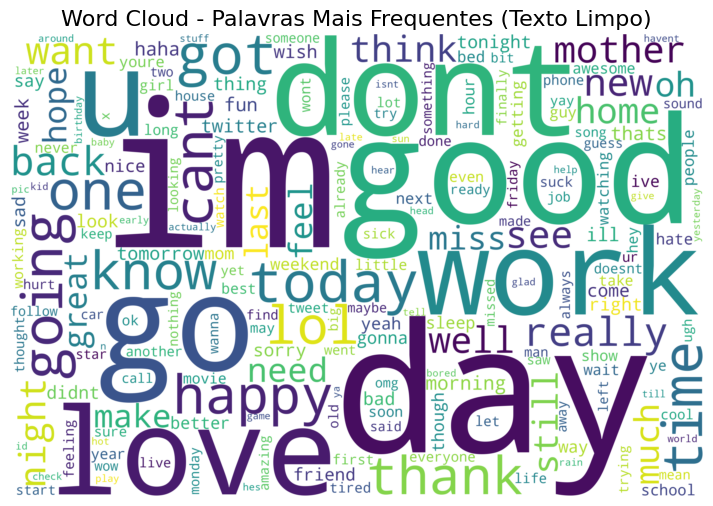

In [ ]:
all_items_clean = ' '.join(df['clean_text'])

wordcloud = WordCloud(
    width=3000,
    height=2000,
    background_color='white',
    colormap='viridis',
    collocations=False,
    max_words=200
).generate(all_items_clean)

# Mostrar a Word Cloud
plt.figure(figsize=(15, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud - Palavras Mais Frequentes (Texto Limpo)', fontsize=16)
plt.show()


### 5.2 Distribuição do Número de Palavras por Sentimento

/tmp/ipykernel_8495/560667323.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sentiment', y='word_count', data=df, palette=sentiment_colors, ax=axes[1])


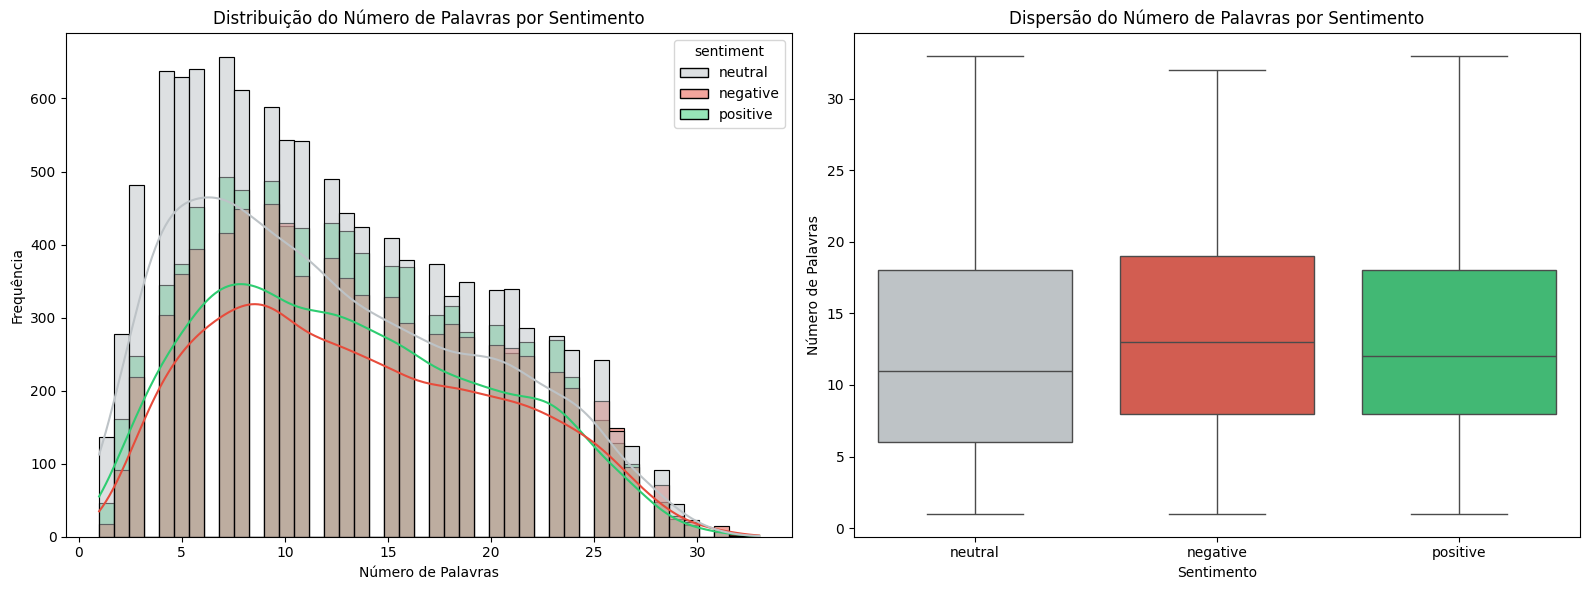

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histograma
sns.histplot(data=df, x='word_count', hue='sentiment', kde=True, palette=sentiment_colors, ax=axes[0])
axes[0].set_title('Distribuição do Número de Palavras por Sentimento')
axes[0].set_xlabel('Número de Palavras')
axes[0].set_ylabel('Frequência')

# Boxplot
sns.boxplot(x='sentiment', y='word_count', data=df, palette=sentiment_colors, ax=axes[1])
axes[1].set_title('Dispersão do Número de Palavras por Sentimento')
axes[1].set_xlabel('Sentimento')
axes[1].set_ylabel('Número de Palavras')

plt.tight_layout()
plt.show()


### 5.3 Palavras mais Frequentes

/tmp/ipykernel_8495/2298931900.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Contagem', y='Palavra', data=df_unigrams, palette='Blues_r', ax=axes[0])
/tmp/ipykernel_8495/2298931900.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Contagem', y='Bigrama', data=df_bigrams, palette='Oranges_r', ax=axes[1])


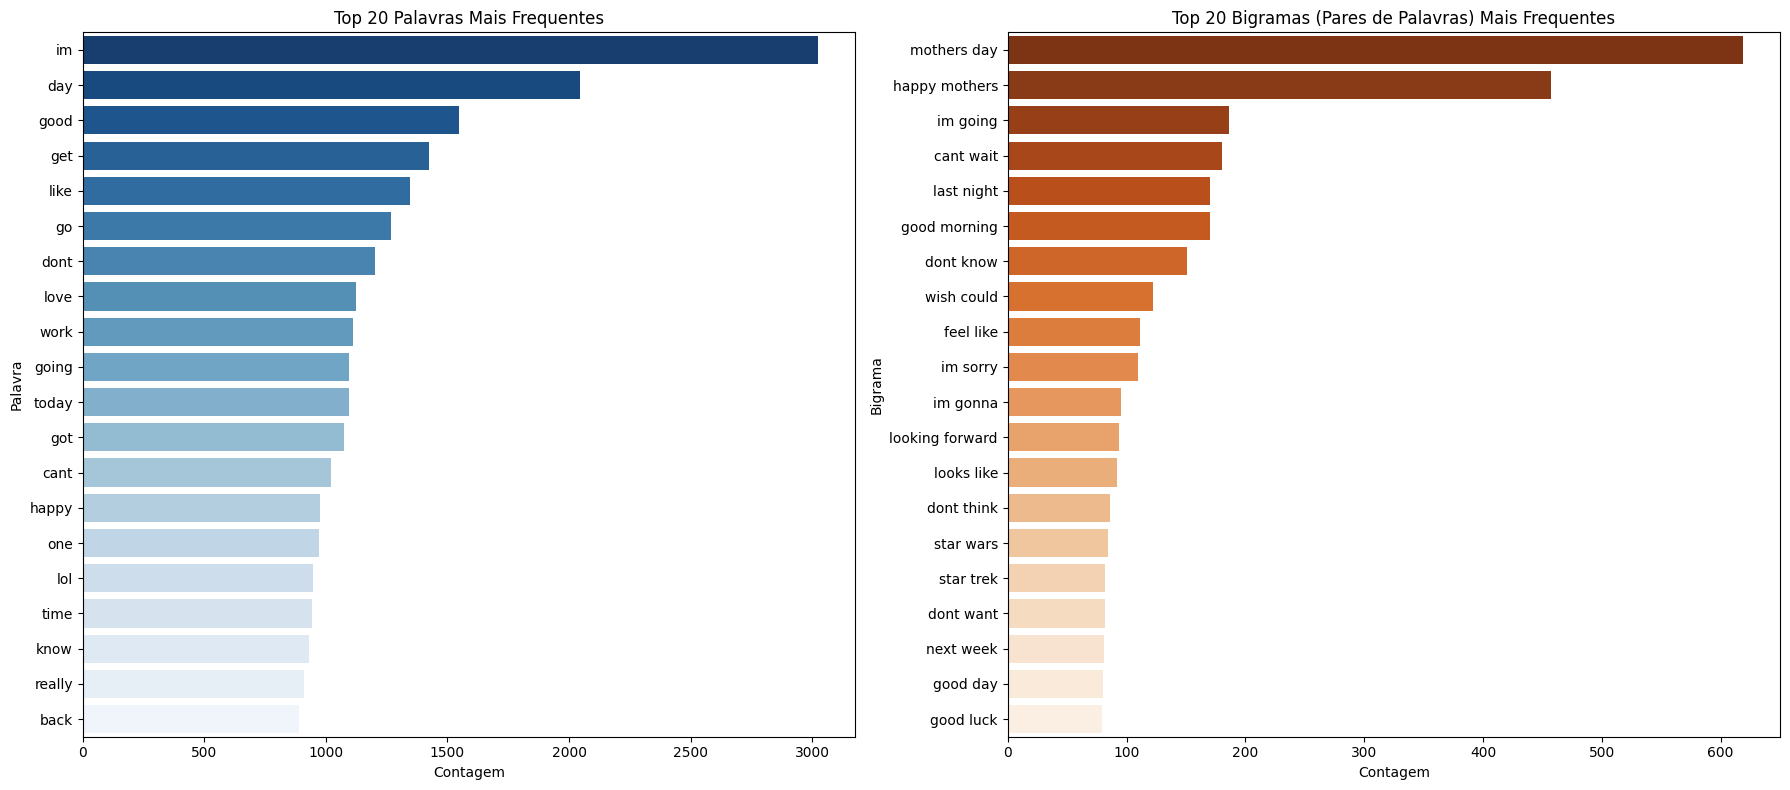

In [ ]:
def get_top_n_words(corpus, n=None, ngram_range=(1,1)):
    vec = CountVectorizer(ngram_range=ngram_range).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

# Extrair Top 20 palavras únicas
top_unigrams = get_top_n_words(df['clean_text'], 20, (1,1))
top_bigrams = get_top_n_words(df['clean_text'], 20, (2,2))

# Converter para DataFrame para facilitar o plot
df_unigrams = pd.DataFrame(top_unigrams, columns=['Palavra', 'Contagem'])
df_bigrams = pd.DataFrame(top_bigrams, columns=['Bigrama', 'Contagem'])

# Criar os gráficos
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

sns.barplot(x='Contagem', y='Palavra', data=df_unigrams, palette='Blues_r', ax=axes[0])
axes[0].set_title('Top 20 Palavras Mais Frequentes')

sns.barplot(x='Contagem', y='Bigrama', data=df_bigrams, palette='Oranges_r', ax=axes[1])
axes[1].set_title('Top 20 Bigramas (Pares de Palavras) Mais Frequentes')

plt.tight_layout()
plt.show()


### 5.4 Análise Temporal e Demográfica


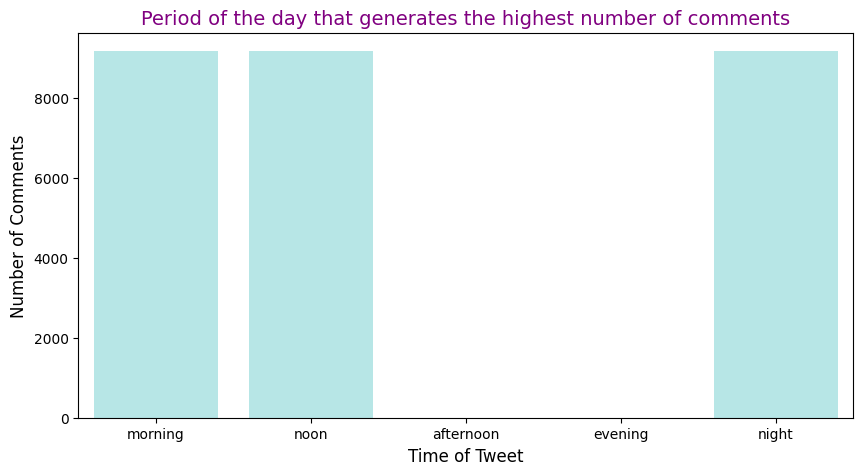

In [ ]:
# Ordenar as fases do dia
ordem_tempo = ['morning', 'noon', 'afternoon', 'evening', 'night']

plt.figure(figsize=(10, 5))
sns.countplot(x='Time of Tweet', data=df, order=ordem_tempo, color='paleturquoise')
plt.xlabel('Time of Tweet', size=12)
plt.ylabel('Number of Comments', size=12)
plt.title('Period of the day that generates the highest number of comments', color='purple', size=14)
plt.show()


### 5.5 Distribuição dos Sentimentos

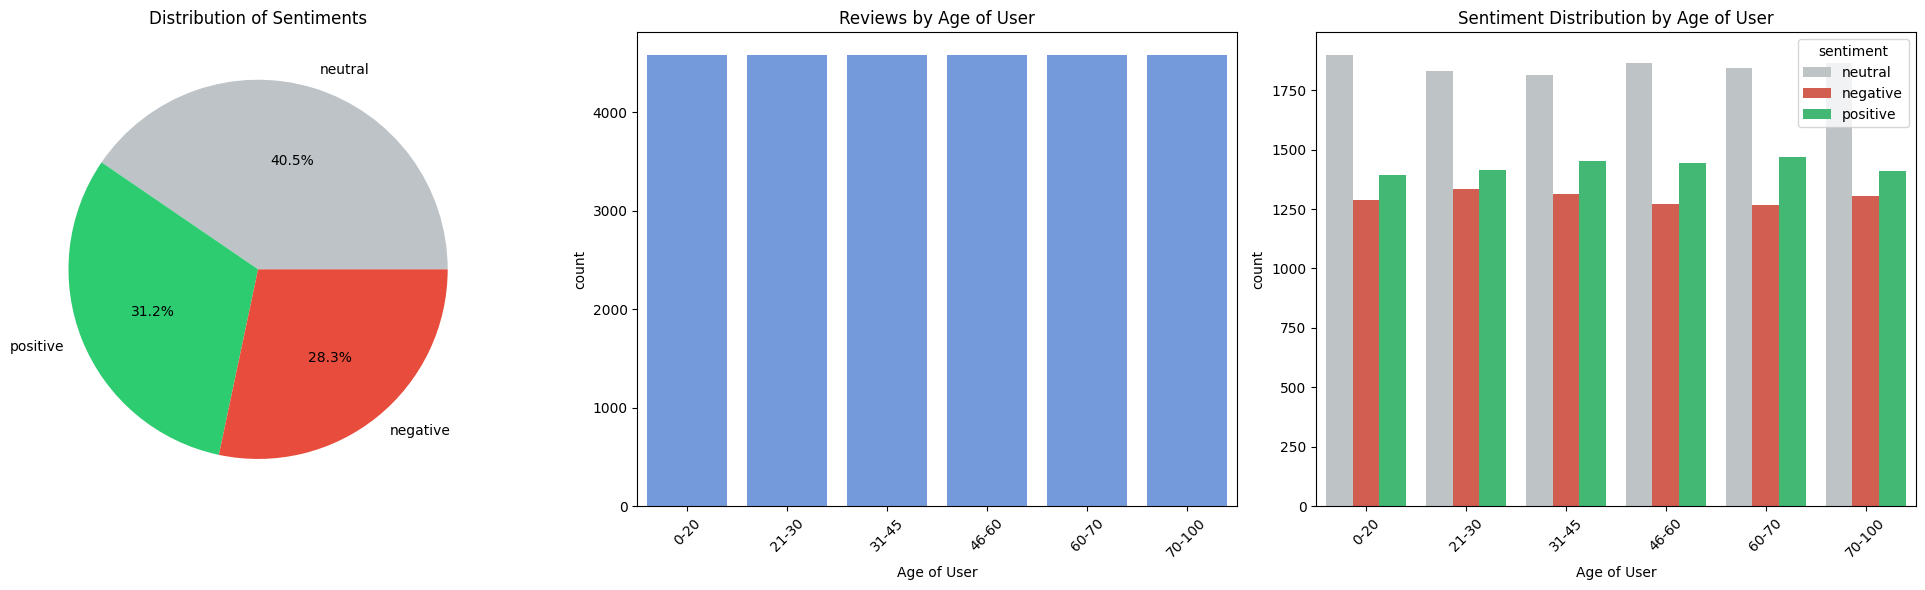

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Pie Chart de Sentimentos
sentiment_counts = df['sentiment'].value_counts()
axes[0].pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%',
            colors=[sentiment_colors.get(x, '#333333') for x in sentiment_counts.index])
axes[0].set_title('Distribution of Sentiments')

# 2. Countplot por Age of User (Ordenado)
ordem_idades = sorted(df['Age of User'].dropna().unique())
sns.countplot(x='Age of User', data=df, order=ordem_idades, color='cornflowerblue', ax=axes[1])
axes[1].set_title('Reviews by Age of User')
axes[1].tick_params(axis='x', rotation=45)

# 3. Age of User vs Sentimento
sns.countplot(x='Age of User', hue="sentiment", data=df, order=ordem_idades, palette=sentiment_colors, ax=axes[2])
axes[2].set_title('Sentiment Distribution by Age of User')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


### 5.6 Sentimento por Período do Dia


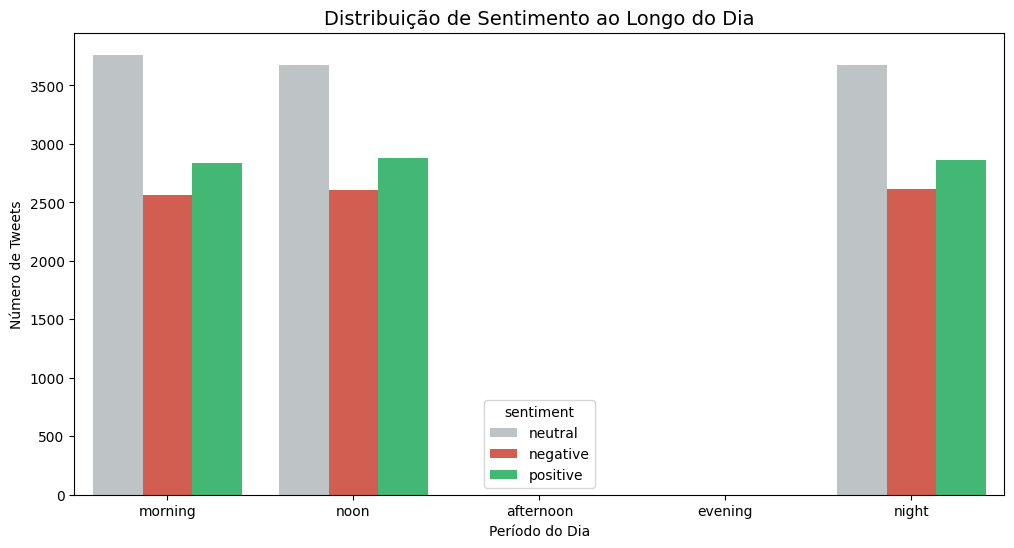

In [ ]:
plt.figure(figsize=(12, 6))
sns.countplot(x='Time of Tweet', hue='sentiment', data=df, order=ordem_tempo, palette=sentiment_colors)
plt.title('Distribuição de Sentimento ao Longo do Dia', fontsize=14)
plt.xlabel('Período do Dia')
plt.ylabel('Número de Tweets')
plt.show()


### 5.7 Distribuição Geográfica


### 5.8 Síntese da Análise Exploratória

A análise exploratória permitiu compreender melhor a estrutura do dataset antes da fase de modelação. O conjunto de dados inicial contém **27,481 observações** e apresenta apenas **1 valor nulo** nas colunas `text` e `selected_text`, o que indica que a qualidade estrutural dos dados é globalmente boa.

A distribuição dos sentimentos mostra que a classe **neutral** é a mais representativa, correspondendo a aproximadamente **40.5%** das observações. As classes **positive** e **negative** representam cerca de **31.2%** e **28.3%**, respetivamente. Esta diferença revela um desequilíbrio inicial e justifica a decisão posterior de simplificar o problema para classificação binária.

A análise do número de palavras demonstra que os textos são, em geral, curtos, concentrando-se sobretudo entre **5 e 20 palavras**. Esta característica é típica de comentários ou publicações curtas e reforça a importância de um pré-processamento cuidadoso, uma vez que cada palavra pode ter impacto relevante na classificação.

A word cloud e os gráficos de frequência mostram a presença de termos muito comuns, como **day**, **good**, **work**, **time**, **today** e **love**. Alguns destes termos têm potencial valor emocional, enquanto outros são demasiado genéricos, justificando a utilização de técnicas como remoção de stopwords, lematização e seleção de atributos.

Também se observa que as faixas etárias estão praticamente equilibradas, com cerca de **4,580 observações por grupo**, o que sugere que esta variável foi distribuída de forma quase uniforme no dataset. Por isso, a modelação principal foi centrada no conteúdo textual, embora as variáveis contextuais tenham sido úteis para caracterização inicial.


In [ ]:
# Contabilizar o número de ocorrências por País (Top 10)
country_counts = df['Country'].value_counts().head(10)
print(country_counts)


Country
Afghanistan            149
Albania                149
Algeria                149
Andorra                149
Angola                 149
Antigua and Barbuda    149
Argentina              149
Armenia                149
Australia              149
Austria                149
Name: count, dtype: int64


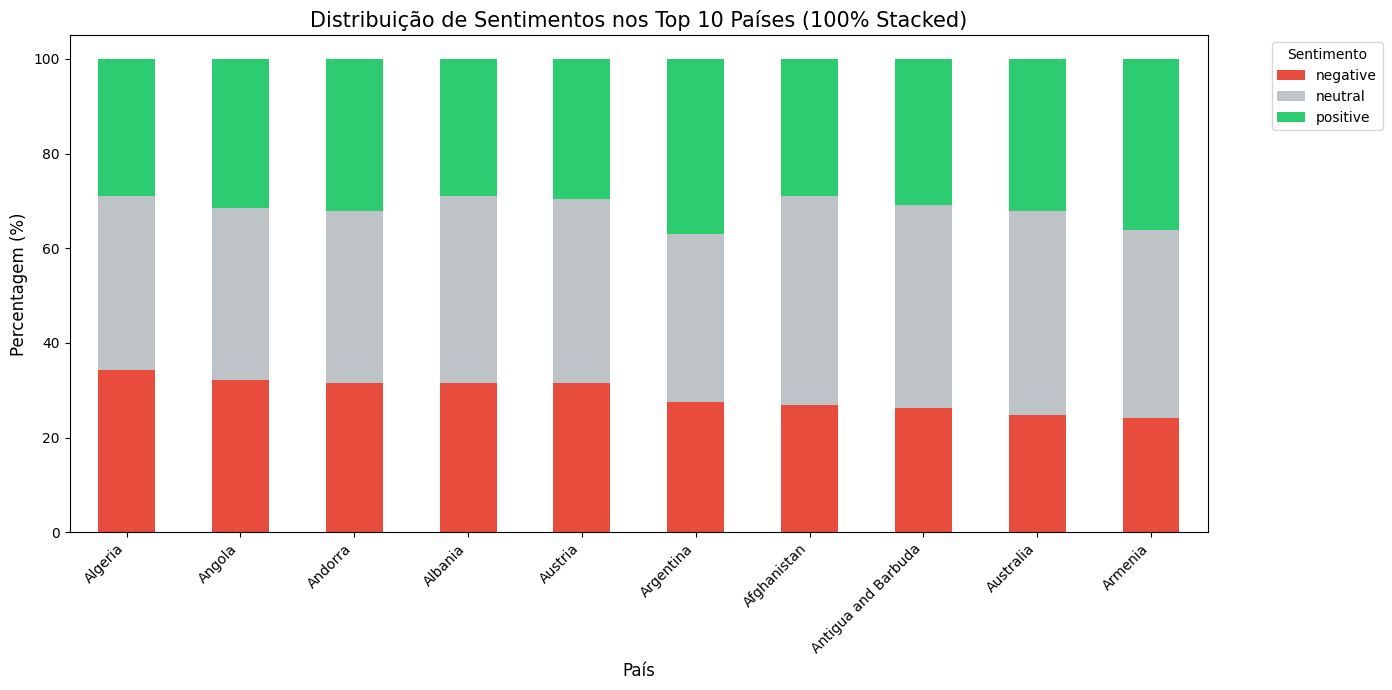

In [ ]:
# Top 10 países com mais tweets
top_countries = df['Country'].value_counts().head(10).index

# Filtrar o dataset apenas para esses 10 países
df_top_countries = df[df['Country'].isin(top_countries)]

country_sentiment = pd.crosstab(df_top_countries['Country'], df_top_countries['sentiment'], normalize='index') * 100

# Ordenar pelos países que têm maior percentagem de sentimento negativo
country_sentiment = country_sentiment.sort_values(by='negative', ascending=False)

country_sentiment.plot(kind='bar', stacked=True, figsize=(14, 7), color=[sentiment_colors.get(col) for col in country_sentiment.columns])
plt.title('Distribuição de Sentimentos nos Top 10 Países (100% Stacked)', fontsize=15)
plt.xlabel('País', fontsize=12)
plt.ylabel('Percentagem (%)', fontsize=12)
plt.legend(title='Sentimento', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# 6. Pré-processamento Avançado para Text Mining

Nesta fase é aplicado um pipeline de pré-processamento textual com o objetivo de reduzir ruído, normalizar a linguagem e preparar os textos para representação numérica.

Após a remoção da classe **neutral**, o dataset fica com **16,363 observações**, distribuídas entre **8,582 exemplos positivos** e **7,781 exemplos negativos**. Apesar de a diferença entre classes não ser extrema, existe uma ligeira predominância da classe positiva, pelo que são posteriormente testadas técnicas de balanceamento.

As técnicas aplicadas incluem:

- remoção da classe neutra;
- identificação de entidades nomeadas (NER);
- remoção de HTML tags e URLs;
- expansão de chatwords;
- expansão de emoticons;
- conversão de emojis em texto;
- conversão para minúsculas;
- expansão de contrações;
- remoção de pontuação;
- remoção de stopwords;
- filtragem de palavras válidas;
- lematização.

Este conjunto de transformações é relevante porque os textos do dataset apresentam linguagem informal, abreviações, pontuação expressiva e ruído típico de conteúdos digitais.


In [ ]:
!pip -q install contractions emoji beautifulsoup4 imbalanced-learn spacy
!python -m spacy download en_core_web_sm -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 29.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# IMPORTS E CONFIGURAÇÃO
import re
import html
import string
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import nltk
import emoji
import contractions
import spacy

from bs4 import BeautifulSoup
from html import unescape
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, words
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from imblearn.over_sampling import RandomOverSampler

# Downloads NLTK
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('words')
nltk.download('wordnet')
nltk.download('omw-1.4')

# spaCy
nlp = spacy.load("en_core_web_sm")

# Configuração principal
TEXT_COL = "text"
TARGET_COL = "sentiment"

# Cópia de trabalho
review_df = df.copy()

review_df[TEXT_COL] = review_df[TEXT_COL].astype(str)

print("Shape inicial:", review_df.shape)
print("Colunas disponíveis:", list(review_df.columns))
display(review_df[[TEXT_COL, TARGET_COL]].head(5))


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Unzipping corpora/words.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Shape inicial: (27480, 13)
Colunas disponíveis: ['textID', 'text', 'selected_text', 'sentiment', 'Time of Tweet', 'Age of User', 'Country', 'Population -2020', 'Land Area (Km²)', 'Density (P/Km²)', 'char_count', 'word_count', 'clean_text']


,text,sentiment
0,"I`d have responded, if I were going",neutral
1,Sooo SAD I will miss you here in San Diego!!!,negative
2,my boss is bullying me...,negative
3,what interview! leave me alone,negative
4,"Sons of ****, why couldn`t they put them on t...",negative


## 6.1 Remoção da Classe Neutra

Para simplificar o problema de classificação, são removidas as reviews com sentimento **neutral**.  
Desta forma, o modelo passa a trabalhar apenas com duas classes:

- **positive**
- **negative**


In [ ]:
# Remover reviews com sentimento neutro
review_df = review_df[review_df[TARGET_COL] != 'neutral'].copy()

print("Distribuição após remoção da classe neutral:")
print(review_df[TARGET_COL].value_counts())
display(review_df[[TEXT_COL, TARGET_COL]].head(10))


Distribuição após remoção da classe neutral:
sentiment
positive    8582
negative    7781
Name: count, dtype: int64


,text,sentiment
1,Sooo SAD I will miss you here in San Diego!!!,negative
2,my boss is bullying me...,negative
3,what interview! leave me alone,negative
4,"Sons of ****, why couldn`t they put them on t...",negative
6,2am feedings for the baby are fun when he is a...,positive
9,Journey!? Wow... u just became cooler. hehe....,positive
11,I really really like the song Love Story by Ta...,positive
12,My Sharpie is running DANGERously low on ink,negative
13,i want to go to music tonight but i lost my vo...,negative
15,"Uh oh, I am sunburned",negative


## 6.2 Identificação de NER (Named Entity Recognition)

Nesta etapa são identificadas entidades nomeadas no texto, tais como pessoas, organizações, localizações e datas.


In [ ]:
def extract_named_entities(texts, model, batch_size=32):
    entities_list = []
    for doc in model.pipe(texts, batch_size=batch_size):
        entities_list.append([(ent.text, ent.label_) for ent in doc.ents])
    return entities_list

# Aplicar NER
review_df['named_entities'] = extract_named_entities(review_df[TEXT_COL].fillna(""), nlp)

display(review_df[[TEXT_COL, 'named_entities']].head(10))


,text,named_entities
1,Sooo SAD I will miss you here in San Diego!!!,"[(San Diego, GPE)]"
2,my boss is bullying me...,[]
3,what interview! leave me alone,[]
4,"Sons of ****, why couldn`t they put them on t...",[]
6,2am feedings for the baby are fun when he is a...,"[(2, CARDINAL)]"
9,Journey!? Wow... u just became cooler. hehe....,[]
11,I really really like the song Love Story by Ta...,"[(Love Story, WORK_OF_ART), (Taylor Swift, PER..."
12,My Sharpie is running DANGERously low on ink,"[(Sharpie, PERSON)]"
13,i want to go to music tonight but i lost my vo...,"[(tonight, TIME)]"
15,"Uh oh, I am sunburned",[]


## 6.3 Remoção de elementos HTML

Antes da normalização textual, procede-se à remoção de etiquetas HTML e entidades codificadas, uma vez que estes elementos introduzem ruído e não acrescentam valor semântico ao processo de classificação.


In [ ]:
review_df['text_without_html'] = review_df[TEXT_COL].apply(unescape)
review_df['text_without_html'] = review_df['text_without_html'].apply(
    lambda x: BeautifulSoup(str(x), "html.parser").get_text(separator=" ")
)

display(review_df[[TEXT_COL, 'text_without_html']].head(10))


,text,text_without_html
1,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD I will miss you here in San Diego!!!
2,my boss is bullying me...,my boss is bullying me...
3,what interview! leave me alone,what interview! leave me alone
4,"Sons of ****, why couldn`t they put them on t...","Sons of ****, why couldn`t they put them on t..."
6,2am feedings for the baby are fun when he is a...,2am feedings for the baby are fun when he is a...
9,Journey!? Wow... u just became cooler. hehe....,Journey!? Wow... u just became cooler. hehe....
11,I really really like the song Love Story by Ta...,I really really like the song Love Story by Ta...
12,My Sharpie is running DANGERously low on ink,My Sharpie is running DANGERously low on ink
13,i want to go to music tonight but i lost my vo...,i want to go to music tonight but i lost my vo...
15,"Uh oh, I am sunburned","Uh oh, I am sunburned"


## 6.4 Remoção de URLs

Nesta etapa são removidos links, endereços `www` e referências URL, por se tratarem de elementos com pouco valor semântico para a análise de sentimentos.


In [ ]:
review_df['text_without_urls'] = review_df['text_without_html'].str.replace(
    r'http\S+|www\S+|https\S+',
    '',
    regex=True
)

display(review_df[['text_without_html', 'text_without_urls']].head(10))


,text_without_html,text_without_urls
1,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD I will miss you here in San Diego!!!
2,my boss is bullying me...,my boss is bullying me...
3,what interview! leave me alone,what interview! leave me alone
4,"Sons of ****, why couldn`t they put them on t...","Sons of ****, why couldn`t they put them on t..."
6,2am feedings for the baby are fun when he is a...,2am feedings for the baby are fun when he is a...
9,Journey!? Wow... u just became cooler. hehe....,Journey!? Wow... u just became cooler. hehe....
11,I really really like the song Love Story by Ta...,I really really like the song Love Story by Ta...
12,My Sharpie is running DANGERously low on ink,My Sharpie is running DANGERously low on ink
13,i want to go to music tonight but i lost my vo...,i want to go to music tonight but i lost my vo...
15,"Uh oh, I am sunburned","Uh oh, I am sunburned"


## 6.5 Expansão de Chatwords

Nesta etapa são identificadas abreviações típicas da comunicação digital e substituídas pela sua forma completa.  

In [ ]:
chatwords = {
    "AFAIK": "As Far As I Know",
    "AFK": "Away From Keyboard",
    "ASAP": "As Soon As Possible",
    "LOL": "laugh out loud",
    "BTW": "By The Way",
    "BRB": "Be Right Back",
    "OMG": "Oh My God",
    "IDK": "I do not know",
    "FYI": "For Your Information",
    "TYT": "Take Your Time",
    "THX": "Thanks",
    "SPK": "Speak"
}

def expand_chatwords(text):
    text = str(text)
    for chatword, meaning in chatwords.items():
        text = re.sub(rf'\b{re.escape(chatword)}\b', meaning, text)
        text = re.sub(rf'\b{re.escape(chatword.lower())}\b', meaning.lower(), text)
    return text

review_df['text_without_chatwords'] = review_df['text_without_urls'].apply(expand_chatwords)

display(review_df[['text_without_urls', 'text_without_chatwords']].head(10))


,text_without_urls,text_without_chatwords
1,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD I will miss you here in San Diego!!!
2,my boss is bullying me...,my boss is bullying me...
3,what interview! leave me alone,what interview! leave me alone
4,"Sons of ****, why couldn`t they put them on t...","Sons of ****, why couldn`t they put them on t..."
6,2am feedings for the baby are fun when he is a...,2am feedings for the baby are fun when he is a...
9,Journey!? Wow... u just became cooler. hehe....,Journey!? Wow... u just became cooler. hehe....
11,I really really like the song Love Story by Ta...,I really really like the song Love Story by Ta...
12,My Sharpie is running DANGERously low on ink,My Sharpie is running DANGERously low on ink
13,i want to go to music tonight but i lost my vo...,i want to go to music tonight but i lost my vo...
15,"Uh oh, I am sunburned","Uh oh, I am sunburned"


## 6.6 Expansão de Emoticons

Os emoticons presentes nas reviews são convertidos em descrições textuais equivalentes, preservando o valor emocional da mensagem.


In [ ]:
emoticons_dict = {
    ":-)": " happy face ",
    ":)": " happy face ",
    ":-(": " sad face ",
    ":(": " sad face ",
    ":-D": " laughing face ",
    ":D": " laughing face ",
    ";-)": " winking face ",
    ";)": " winking face ",
    ":-/": " confused face ",
    ":/": " confused face "
}

def expand_emoticons(text):
    text = str(text)
    for emoticon, meaning in emoticons_dict.items():
        text = text.replace(emoticon, meaning)
    return text

review_df['text_without_emoticons'] = review_df['text_without_chatwords'].apply(expand_emoticons)

display(review_df[['text_without_chatwords', 'text_without_emoticons']].head(10))


,text_without_chatwords,text_without_emoticons
1,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD I will miss you here in San Diego!!!
2,my boss is bullying me...,my boss is bullying me...
3,what interview! leave me alone,what interview! leave me alone
4,"Sons of ****, why couldn`t they put them on t...","Sons of ****, why couldn`t they put them on t..."
6,2am feedings for the baby are fun when he is a...,2am feedings for the baby are fun when he is a...
9,Journey!? Wow... u just became cooler. hehe....,Journey!? Wow... u just became cooler. hehe....
11,I really really like the song Love Story by Ta...,I really really like the song Love Story by Ta...
12,My Sharpie is running DANGERously low on ink,My Sharpie is running DANGERously low on ink
13,i want to go to music tonight but i lost my vo...,i want to go to music tonight but i lost my vo...
15,"Uh oh, I am sunburned","Uh oh, I am sunburned"


## 6.7 Conversão de Emojis em Texto

Os emojis são convertidos em descrições textuais, permitindo preservar informação semântica e afetiva relevante para a análise de sentimentos.


In [ ]:
review_df['text_no_emojis'] = review_df['text_without_emoticons'].apply(
    lambda x: emoji.demojize(str(x), delimiters=(" ", " "))
)

display(review_df[['text_without_emoticons', 'text_no_emojis']].head(10))


,text_without_emoticons,text_no_emojis
1,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD I will miss you here in San Diego!!!
2,my boss is bullying me...,my boss is bullying me...
3,what interview! leave me alone,what interview! leave me alone
4,"Sons of ****, why couldn`t they put them on t...","Sons of ****, why couldn`t they put them on t..."
6,2am feedings for the baby are fun when he is a...,2am feedings for the baby are fun when he is a...
9,Journey!? Wow... u just became cooler. hehe....,Journey!? Wow... u just became cooler. hehe....
11,I really really like the song Love Story by Ta...,I really really like the song Love Story by Ta...
12,My Sharpie is running DANGERously low on ink,My Sharpie is running DANGERously low on ink
13,i want to go to music tonight but i lost my vo...,i want to go to music tonight but i lost my vo...
15,"Uh oh, I am sunburned","Uh oh, I am sunburned"


## 6.8 Conversão para Minúsculas

A conversão para minúsculas uniformiza a representação textual e evita que palavras semanticamente idênticas sejam tratadas como diferentes apenas por causa da capitalização.


In [ ]:
review_df['lower_text'] = review_df['text_no_emojis'].str.lower()

display(review_df[['text_no_emojis', 'lower_text']].head(10))


,text_no_emojis,lower_text
1,Sooo SAD I will miss you here in San Diego!!!,sooo sad i will miss you here in san diego!!!
2,my boss is bullying me...,my boss is bullying me...
3,what interview! leave me alone,what interview! leave me alone
4,"Sons of ****, why couldn`t they put them on t...","sons of ****, why couldn`t they put them on t..."
6,2am feedings for the baby are fun when he is a...,2am feedings for the baby are fun when he is a...
9,Journey!? Wow... u just became cooler. hehe....,journey!? wow... u just became cooler. hehe....
11,I really really like the song Love Story by Ta...,i really really like the song love story by ta...
12,My Sharpie is running DANGERously low on ink,my sharpie is running dangerously low on ink
13,i want to go to music tonight but i lost my vo...,i want to go to music tonight but i lost my vo...
15,"Uh oh, I am sunburned","uh oh, i am sunburned"


## 6.9 Expansão de Contrações

As contrações em inglês são expandidas para a sua forma completa.

In [ ]:
review_df['text_without_contractions'] = review_df['lower_text'].apply(contractions.fix)

display(review_df[['lower_text', 'text_without_contractions']].head(10))


,lower_text,text_without_contractions
1,sooo sad i will miss you here in san diego!!!,sooo sad i will miss you here in san diego!!!
2,my boss is bullying me...,my boss is bullying me...
3,what interview! leave me alone,what interview! leave me alone
4,"sons of ****, why couldn`t they put them on t...","sons of ****, why couldn`t they put them on t..."
6,2am feedings for the baby are fun when he is a...,2am feedings for the baby are fun when he is a...
9,journey!? wow... u just became cooler. hehe....,journey!? wow... you just became cooler. heh...
11,i really really like the song love story by ta...,i really really like the song love story by ta...
12,my sharpie is running dangerously low on ink,my sharpie is running dangerously low on ink
13,i want to go to music tonight but i lost my vo...,i want to go to music tonight but i lost my vo...
15,"uh oh, i am sunburned","uh oh, i am sunburned"


## 6.10 Remoção de Pontuação

São removidos sinais de pontuação e caracteres especiais, preservando apenas letras, números e espaços.


In [ ]:
review_df['text_without_punctuation'] = review_df['text_without_contractions'].str.replace(
    r'[^\w\s]',
    ' ',
    regex=True
).str.replace(r'\s+', ' ', regex=True).str.strip()

display(review_df[['text_without_contractions', 'text_without_punctuation']].head(10))


,text_without_contractions,text_without_punctuation
1,sooo sad i will miss you here in san diego!!!,sooo sad i will miss you here in san diego
2,my boss is bullying me...,my boss is bullying me
3,what interview! leave me alone,what interview leave me alone
4,"sons of ****, why couldn`t they put them on t...",sons of why couldn t they put them on the rele...
6,2am feedings for the baby are fun when he is a...,2am feedings for the baby are fun when he is a...
9,journey!? wow... you just became cooler. heh...,journey wow you just became cooler hehe is tha...
11,i really really like the song love story by ta...,i really really like the song love story by ta...
12,my sharpie is running dangerously low on ink,my sharpie is running dangerously low on ink
13,i want to go to music tonight but i lost my vo...,i want to go to music tonight but i lost my voice
15,"uh oh, i am sunburned",uh oh i am sunburned


## 6.11 Remoção de StopWords

As *stopwords* são palavras muito frequentes, mas com baixo poder discriminativo para tarefas de classificação de sentimentos.  
Nesta etapa são removidas da representação textual.


In [ ]:
stop_words = set(stopwords.words('english'))

def remove_stopwords(text):
    tokens = word_tokenize(str(text))
    filtered_words = [word for word in tokens if word.lower() not in stop_words]
    return ' '.join(filtered_words)

review_df['text_without_stopwords'] = review_df['text_without_punctuation'].apply(remove_stopwords)

display(review_df[['text_without_punctuation', 'text_without_stopwords']].head(10))


,text_without_punctuation,text_without_stopwords
1,sooo sad i will miss you here in san diego,sooo sad miss san diego
2,my boss is bullying me,boss bullying
3,what interview leave me alone,interview leave alone
4,sons of why couldn t they put them on the rele...,sons put releases already bought
6,2am feedings for the baby are fun when he is a...,2am feedings baby fun smiles coos
9,journey wow you just became cooler hehe is tha...,journey wow became cooler hehe possible
11,i really really like the song love story by ta...,really really like song love story taylor swift
12,my sharpie is running dangerously low on ink,sharpie running dangerously low ink
13,i want to go to music tonight but i lost my voice,want go music tonight lost voice
15,uh oh i am sunburned,uh oh sunburned


## 6.12 Filtragem de Palavras Válidas

Nesta fase são mantidas apenas palavras existentes num dicionário de referência da língua inglesa, reduzindo ruído associado a erros ortográficos, símbolos residuais ou tokens pouco informativos.


In [ ]:
valid_words = set(word.lower() for word in words.words())

def keep_valid_words(text):
    tokens = word_tokenize(str(text))
    filtered_tokens = [token for token in tokens if token.lower() in valid_words]
    return ' '.join(filtered_tokens)

review_df['text_valid_words'] = review_df['text_without_stopwords'].apply(keep_valid_words)

display(review_df[['text_without_stopwords', 'text_valid_words']].head(10))


,text_without_stopwords,text_valid_words
1,sooo sad miss san diego,sad miss san diego
2,boss bullying,boss bullying
3,interview leave alone,interview leave alone
4,sons put releases already bought,sons put already bought
6,2am feedings baby fun smiles coos,baby fun coos
9,journey wow became cooler hehe possible,journey wow cooler hehe possible
11,really really like song love story taylor swift,really really like song love story taylor swift
12,sharpie running dangerously low ink,sharpie running dangerously low ink
13,want go music tonight lost voice,want go music tonight lost voice
15,uh oh sunburned,oh sunburned


## 6.13 Lematização

A lematização reduz cada palavra à sua forma base (*lemma*), preservando melhor o significado linguístico.  
Para garantir estabilidade na execução do notebook, é utilizada a lematização simples com `WordNetLemmatizer`.


In [ ]:
lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    tokens = word_tokenize(str(text))
    lemmas = [lemmatizer.lemmatize(word) for word in tokens]
    return ' '.join(lemmas)

review_df['text_preprocessed'] = review_df['text_valid_words'].apply(lemmatize_text)

display(review_df[[TEXT_COL, 'text_preprocessed', TARGET_COL]].head(10))


,text,text_preprocessed,sentiment
1,Sooo SAD I will miss you here in San Diego!!!,sad miss san diego,negative
2,my boss is bullying me...,bos bullying,negative
3,what interview! leave me alone,interview leave alone,negative
4,"Sons of ****, why couldn`t they put them on t...",son put already bought,negative
6,2am feedings for the baby are fun when he is a...,baby fun coo,positive
9,Journey!? Wow... u just became cooler. hehe....,journey wow cooler hehe possible,positive
11,I really really like the song Love Story by Ta...,really really like song love story taylor swift,positive
12,My Sharpie is running DANGERously low on ink,sharpie running dangerously low ink,negative
13,i want to go to music tonight but i lost my vo...,want go music tonight lost voice,negative
15,"Uh oh, I am sunburned",oh sunburned,negative


## 6.14 Resultado Final do Pré-processamento

A coluna `text_preprocessed` contém a versão final dos textos após limpeza, normalização e lematização. Esta coluna passa a ser a base para a vetorização e para o treino dos modelos.

Após o pré-processamento e a remoção da classe neutra, o dataset apresenta **16,363 observações**, sem valores nulos na coluna final de texto. A distribuição das classes fica relativamente equilibrada, com **8,582 textos positivos** e **7,781 textos negativos**.

Embora exista uma ligeira predominância da classe positiva, a diferença não é suficientemente elevada para comprometer totalmente o treino. Ainda assim, a aplicação de técnicas de balanceamento é adequada para reduzir possíveis enviesamentos dos classificadores.


In [ ]:
print("Número de linhas após pré-processamento:", len(review_df))
print("Valores nulos em text_preprocessed:", review_df['text_preprocessed'].isnull().sum())
print("\nDistribuição atual das classes:")
print(review_df[TARGET_COL].value_counts())

display(review_df[[TEXT_COL, 'text_preprocessed', TARGET_COL]].head(10))


Número de linhas após pré-processamento: 16363
Valores nulos em text_preprocessed: 0

Distribuição atual das classes:
sentiment
positive    8582
negative    7781
Name: count, dtype: int64


,text,text_preprocessed,sentiment
1,Sooo SAD I will miss you here in San Diego!!!,sad miss san diego,negative
2,my boss is bullying me...,bos bullying,negative
3,what interview! leave me alone,interview leave alone,negative
4,"Sons of ****, why couldn`t they put them on t...",son put already bought,negative
6,2am feedings for the baby are fun when he is a...,baby fun coo,positive
9,Journey!? Wow... u just became cooler. hehe....,journey wow cooler hehe possible,positive
11,I really really like the song Love Story by Ta...,really really like song love story taylor swift,positive
12,My Sharpie is running DANGERously low on ink,sharpie running dangerously low ink,negative
13,i want to go to music tonight but i lost my vo...,want go music tonight lost voice,negative
15,"Uh oh, I am sunburned",oh sunburned,negative


# 7. Técnicas de Balanceamento

Após a remoção da classe neutra, o problema passa a ser binário, envolvendo apenas as classes **positive** e **negative**. Embora a diferença entre as duas classes não seja extrema, existe uma ligeira predominância da classe positiva, o que pode influenciar o comportamento dos classificadores.

Para garantir uma base de treino equilibrada, foi utilizada a técnica de oversampling. Esta abordagem aumenta a representação da classe minoritária até igualar a classe maioritária, sem eliminar observações originalmente disponíveis. Esta decisão é adequada para o contexto de análise de sentimentos, uma vez que cada comentário pode conter padrões linguísticos úteis para a aprendizagem dos modelos.

Assim, a etapa de balanceamento permite reduzir o risco de enviesamento para a classe mais frequente e contribui para uma avaliação mais justa dos classificadores.


In [ ]:
print("Distribuição original das classes:")
print(review_df[TARGET_COL].value_counts())


Distribuição original das classes:
sentiment
positive    8582
negative    7781
Name: count, dtype: int64


## 7.1 Aplicação de Oversampling

**Para evitar *data leakage*, a divisão treino/teste é feita primeiro**, e o oversampling é aplicado **apenas ao conjunto de treino** (mais à frente, sobre a matriz de treino), nunca ao conjunto de teste. Assim, o teste mantém a distribuição real dos dados e nenhuma observação de teste é duplicada para o treino. O mesmo princípio é seguido na vetorização e na seleção de atributos, ajustadas exclusivamente com dados de treino.


In [ ]:
# === Divisao treino/teste ANTES de qualquer ajuste, para evitar data leakage ===
# A divisao e feita sobre o texto pre-processado, ANTES da vetorizacao, da selecao de
# atributos e do oversampling. Assim, nenhuma informacao do conjunto de teste influencia
# estas etapas. O oversampling sera aplicado mais a frente, apenas a matriz de treino.
from sklearn.model_selection import train_test_split

text_train, text_test, y_train, y_test = train_test_split(
    review_df['text_preprocessed'],
    review_df[TARGET_COL],
    test_size=0.30,
    random_state=0,
    shuffle=True,
    stratify=review_df[TARGET_COL]
)

# Guardar a versao NAO balanceada dos rotulos de treino (necessaria para a CV sem leakage)
y_train_unbal = y_train.copy()

print('Tamanho treino:', len(text_train), '| Tamanho teste:', len(text_test))
print('\nDistribuicao das classes no treino (antes do balanceamento):')
print(y_train.value_counts())

Tamanho treino: 11454 | Tamanho teste: 4909

Distribuicao das classes no treino (antes do balanceamento):
sentiment
positive    6007
negative    5447
Name: count, dtype: int64


# 8. Feature Selection – Seleção dos Melhores Atributos

Após o pré-processamento textual, os dados foram divididos em treino e teste antes de qualquer transformação estatística, de forma a evitar *data leakage*. Em seguida, os textos foram convertidos para uma representação numérica através de **TF-IDF**, ajustada exclusivamente no conjunto de treino.

Inicialmente, foram considerados até **5,000 atributos**, correspondentes aos termos mais relevantes do corpus de treino. Em seguida, foi aplicada a técnica **SelectKBest** com teste **Qui-Quadrado**, reduzindo o espaço de atributos para **1,000 features**.

Esta redução representa uma diminuição de cerca de **80%** da dimensionalidade inicial, mantendo apenas os termos com maior associação estatística à variável alvo no conjunto de treino. Esta etapa contribui para melhorar a eficiência computacional, reduzir ruído e diminuir o risco de overfitting, preservando a independência do conjunto de teste.

## 8.1 Vetorização com TF-IDF

O **TF-IDF é ajustado apenas no conjunto de treino** (`fit` no treino, `transform` no teste), garantindo que o vocabulário e os pesos IDF não incorporam informação do conjunto de teste. Os textos pré-processados são assim transformados numa matriz numérica de forma metodologicamente correta.

A opção por TF-IDF é adequada porque atribui maior peso a termos relevantes para cada documento e reduz a influência de palavras demasiado frequentes no corpus. Esta representação é particularmente útil em modelos tradicionais de Machine Learning aplicados a texto, como SVM, Naive Bayes e Logistic Regression.


In [ ]:
# TF-IDF ajustado APENAS no conjunto de treino (fit no treino, transform no teste)
vectorizer = TfidfVectorizer(max_features=5000)
X_tfidf_train = vectorizer.fit_transform(text_train)
X_tfidf_test = vectorizer.transform(text_test)

print('Shape TF-IDF treino:', X_tfidf_train.shape)
print('Shape TF-IDF teste :', X_tfidf_test.shape)

Shape TF-IDF treino: (11454, 5000)
Shape TF-IDF teste : (4909, 5000)


## 8.2 Seleção dos melhores atributos com Qui-Quadrado

A técnica `SelectKBest` com `chi2` permite identificar os termos com maior relação estatística com a variável alvo. A seleção é feita **apenas com os rótulos de treino**, evitando que a escolha das features seja influenciada pelo conjunto de teste.


In [ ]:
# Selecao de atributos (Qui-Quadrado) ajustada APENAS com dados de treino
feature_names = np.array(vectorizer.get_feature_names_out())
k_features = min(1000, X_tfidf_train.shape[1])

selector = SelectKBest(score_func=chi2, k=k_features)
selector.fit(X_tfidf_train, y_train)   # usa apenas rotulos de treino

selected_mask = selector.get_support()
best_features = feature_names[selected_mask]

print('Numero de features selecionadas:', len(best_features))
print('\nPrimeiras 30 melhores features:')
print(best_features[:30])

Numero de features selecionadas: 1000

Primeiras 30 melhores features:
['abandoned' 'access' 'accident' 'accidentally' 'accomplished' 'ace' 'ach'
 'ache' 'aching' 'acid' 'activity' 'actor' 'actress' 'ad' 'added'
 'addiction' 'adorable' 'adore' 'adult' 'advantage' 'advice' 'afford'
 'afraid' 'afternoon' 'age' 'agree' 'ahead' 'airport' 'ako' 'alarm']


## 8.3 Resumo dos objetos finais

No final desta fase ficam disponíveis os seguintes objetos principais para a etapa de classificação:

- `review_df` → dataset pré-processado após remoção da classe neutra;
- `text_train` e `text_test` → textos de treino e teste, definidos antes da vetorização;
- `y_train_unbal` e `y_test` → rótulos originais de treino e teste antes do balanceamento;
- `vectorizer` → vetorizador TF-IDF ajustado apenas ao conjunto de treino;
- `selector` → seletor Qui-Quadrado ajustado apenas com dados de treino;
- `best_features` → lista dos 1,000 atributos mais relevantes;
- `X_train_unbal` → matriz de treino antes do oversampling;
- `X_train` e `y_train` → matriz e rótulos de treino após oversampling;
- `X_test` e `y_test` → matriz e rótulos de teste mantidos intactos, sem duplicação.

Esta organização garante uma sequência metodológica mais rigorosa: primeiro é feita a divisão treino/teste, depois a vetorização e seleção de atributos são ajustadas apenas no treino, e o oversampling é aplicado apenas ao conjunto de treino.

# 9. Classificação – Criação do Modelo

Nesta fase, os textos pré-processados são convertidos numa matriz documento-termo e utilizados para treinar modelos supervisionados de classificação.

Após a divisão estratificada dos dados, o conjunto de treino original ficou com **11,454 observações** e o conjunto de teste com **4,909 observações**. A vetorização TF-IDF e a seleção de atributos foram ajustadas apenas com o conjunto de treino, resultando numa representação final com **1,000 atributos**.

O oversampling foi aplicado apenas ao conjunto de treino, aumentando a classe minoritária até igualar a maioritária. Assim, a matriz final de treino passou a ter **12,014 observações** balanceadas, com **6,007 exemplos positivos** e **6,007 exemplos negativos**. O conjunto de teste manteve a distribuição real dos dados, com **2,575 exemplos positivos** e **2,334 exemplos negativos**, permitindo uma avaliação mais rigorosa e sem duplicações artificiais.

## 9.1. Importação das bibliotecas para classificação

São importadas as bibliotecas necessárias para:
- divisão treino/teste;
- treino de classificadores;
- validação cruzada;
- cálculo das métricas de avaliação;
- visualização da matriz de confusão.


In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    cohen_kappa_score,
    ConfusionMatrixDisplay
)


## 9.2. Criação da Matriz Documento-Termo com TF-IDF

Após a seleção dos melhores atributos com Qui-Quadrado, é criada uma nova representação TF-IDF usando apenas o vocabulário mais relevante.

Desta forma, o modelo é treinado com uma matriz documento-termo mais compacta e discriminativa.


In [ ]:
# Vetorizador final (apenas com as melhores features), ajustado SO no treino
vectorizer_model = TfidfVectorizer(vocabulary=list(best_features))
X_train_unbal = vectorizer_model.fit_transform(text_train)   # treino (ainda nao balanceado)
X_test = vectorizer_model.transform(text_test)               # teste intacto

# Oversampling aplicado APENAS ao treino, depois do split (o teste nunca e duplicado)
ros = RandomOverSampler(random_state=42)
X_train, y_train = ros.fit_resample(X_train_unbal, y_train_unbal)

print('Shape treino (apos oversampling):', X_train.shape)
print('Shape teste  (intacto):', X_test.shape)
print('\nDistribuicao y_train (balanceado):')
print(pd.Series(y_train).value_counts())
print('\nDistribuicao y_test (real, nao balanceado):')
print(pd.Series(y_test).value_counts())

Shape treino (apos oversampling): (12014, 1000)
Shape teste  (intacto): (4909, 1000)

Distribuicao y_train (balanceado):
sentiment
negative    6007
positive    6007
Name: count, dtype: int64

Distribuicao y_test (real, nao balanceado):
sentiment
positive    2575
negative    2334
Name: count, dtype: int64


## 9.3. Divisão em Dados de Treino e Teste

A divisão **estratificada de 70%/30%** foi realizada no início (secção 7), **antes** da vetorização, da seleção de atributos e do oversampling, de forma a evitar *data leakage*. Nesta fase apenas se confirmam as dimensões finais das matrizes de treino e teste.


In [ ]:
# A divisao treino/teste foi feita no inicio (seccao 7), ANTES da vetorizacao e do
# oversampling, para garantir uma avaliacao sem data leakage. Aqui apenas se confirmam
# as dimensoes finais usadas na modelacao.
print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print('\nDistribuicao y_train (treino balanceado):')
print(pd.Series(y_train).value_counts())
print('\nDistribuicao y_test (teste real):')
print(pd.Series(y_test).value_counts())

X_train shape: (12014, 1000)
X_test shape: (4909, 1000)

Distribuicao y_train (treino balanceado):
sentiment
negative    6007
positive    6007
Name: count, dtype: int64

Distribuicao y_test (teste real):
sentiment
positive    2575
negative    2334
Name: count, dtype: int64


## 9.4. Treino do Modelo de Classificação

Os classificadores mais usados em análise de sentimentos incluem **SVM, Logistic Regression, K-NN, Decision Trees** e outros modelos supervisionados.

Neste notebook, o classificador principal selecionado é o **SVM**, mantendo-se no código outras alternativas para testes comparativos.


In [ ]:
np.random.seed(0)

# Classificador principal
classifier = SVC(kernel='linear', probability=True, random_state=0)

# Outros classificadores possíveis para comparação
# classifier = LogisticRegression(max_iter=2000, random_state=0)
# classifier = MultinomialNB()
# classifier = KNeighborsClassifier(n_neighbors=5)
# classifier = DecisionTreeClassifier(random_state=0)
# classifier = RandomForestClassifier(random_state=0)
# classifier = AdaBoostClassifier(random_state=0)
# classifier = GradientBoostingClassifier(random_state=0)

# Treinar modelo
classifier.fit(X_train, y_train)

print("Classificador treinado com sucesso:")
print(classifier)


Classificador treinado com sucesso:
SVC(kernel='linear', probability=True, random_state=0)


## 9.5. Validação Cruzada

A **K-fold Cross Validation** é uma técnica importante para avaliar o desempenho do modelo e reduzir o risco de overfitting.

Aqui é utilizada uma validação cruzada estratificada com **5 folds** sobre o conjunto total de dados.


In [ ]:
# Validacao cruzada SEM leakage: o oversampling e feito DENTRO de cada fold de treino,
# atraves de um pipeline imblearn, usando o treino ainda nao balanceado.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_pipeline = ImbPipeline([
    ('over', RandomOverSampler(random_state=42)),
    ('clf', SVC(kernel='linear', probability=True, random_state=0))
])
cv_scores = cross_val_score(cv_pipeline, X_train_unbal, y_train_unbal, cv=cv, scoring='accuracy')

print('Accuracy por fold:', np.round(cv_scores, 4))
print('Accuracy media CV:', round(cv_scores.mean(), 4))
print('Desvio padrao CV:', round(cv_scores.std(), 4))

Accuracy por fold: [0.8477 0.8533 0.8503 0.8625 0.8515]
Accuracy media CV: 0.8531
Desvio padrao CV: 0.0051


# 10. Avaliação do Modelo

Após o treino do classificador principal, o desempenho do modelo é avaliado no conjunto de teste.

Nesta fase são analisadas diferentes métricas de avaliação, incluindo accuracy, precision, recall, specificity, F1-score, Kappa e error rate. Para além destas métricas, é também apresentada a matriz de confusão, permitindo observar de forma mais detalhada os acertos e erros do modelo.

Esta avaliação permite compreender não apenas a taxa global de acerto, mas também o comportamento do modelo perante cada classe.

## 10.1. Previsões no Conjunto de Teste


In [ ]:
y_pred = classifier.predict(X_test)

print("Primeiras 20 previsões:")
print(y_pred[:20])


Primeiras 20 previsões:
['positive' 'positive' 'positive' 'negative' 'negative' 'positive'
 'negative' 'negative' 'positive' 'positive' 'negative' 'positive'
 'positive' 'negative' 'positive' 'negative' 'positive' 'negative'
 'negative' 'negative']


## 10.2. Matriz de Confusão


In [ ]:
# Matriz de confusão do classificador principal (SVM)
# Calculada com a ordem de classes ['negative', 'positive'] para que o
# desempacotamento tn, fp, fn, tp fique correto e seja reutilizado nas
# métricas (por exemplo, no cálculo da specificity).
cm = confusion_matrix(y_test, y_pred, labels=['negative', 'positive'])
tn, fp, fn, tp = cm.ravel()

print("Matriz de confusão (linhas = real, colunas = previsto) [negative, positive]:")
print(cm)

Matriz de confusão (linhas = real, colunas = previsto) [negative, positive]:
[[2022  312]
 [ 503 2072]]


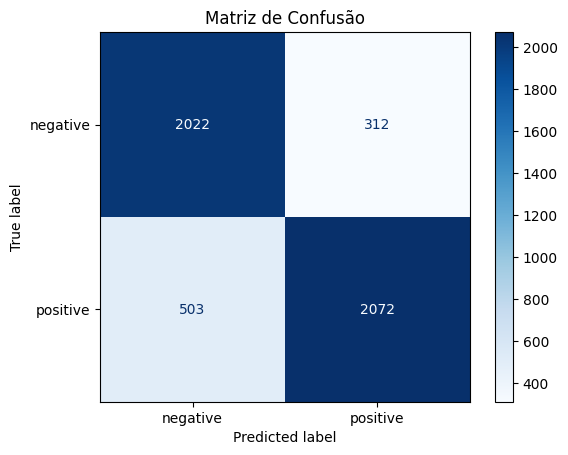

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classifier.classes_)
disp.plot(cmap='Blues')
plt.title("Matriz de Confusão")
plt.show()


## 10.3. Métricas de Avaliação


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label='positive')
recall = recall_score(y_test, y_pred, pos_label='positive')
f1 = f1_score(y_test, y_pred, pos_label='positive')
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
kappa = cohen_kappa_score(y_test, y_pred)
error_rate = 1 - accuracy

metrics_df = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall / Sensitivity', 'Specificity', 'F1-Score', 'Kappa', 'Error Rate'],
    'Valor': [accuracy, precision, recall, specificity, f1, kappa, error_rate]
})

display(metrics_df)


,Métrica,Valor
0,Accuracy,0.833978
1,Precision,0.869128
2,Recall / Sensitivity,0.804660
3,Specificity,0.866324
4,F1-Score,0.835652
5,Kappa,0.668424
6,Error Rate,0.166022


In [ ]:
print("Relatório de Classificação:\n")
print(classification_report(y_test, y_pred))


Relatório de Classificação:

              precision    recall  f1-score   support

    negative       0.80      0.87      0.83      2334
    positive       0.87      0.80      0.84      2575

    accuracy                           0.83      4909
   macro avg       0.83      0.84      0.83      4909
weighted avg       0.84      0.83      0.83      4909



## 10.4. Resumo Interpretativo

Os resultados do SVM mostram um desempenho equilibrado, embora ligeiramente inferior aos valores obtidos em versões anteriores do pipeline. Esta diferença é esperada, uma vez que o pipeline foi corrigido para evitar *data leakage*, aplicando a divisão treino/teste antes da vetorização, da seleção de atributos e do oversampling.

A **accuracy de 0.8340** indica que cerca de 83.4% das observações do conjunto de teste foram corretamente classificadas. A **precision de 0.8691** é superior ao **recall de 0.8047**, o que sugere que o modelo é mais conservador na atribuição da classe positiva: quando prevê positivo, geralmente acerta, mas ainda deixa escapar alguns casos positivos reais.

A **specificity de 0.8663** demonstra uma boa capacidade de identificação da classe negativa. Assim, o modelo apresenta um comportamento relativamente equilibrado entre a deteção de comentários negativos e positivos.

O **F1-score de 0.8357** confirma um bom equilíbrio entre precision e recall, enquanto o **Kappa de 0.6684** indica uma concordância substancial entre as previsões do modelo e as classes reais, acima do que seria esperado por acaso.

# 11. Comparação Estruturada entre Classificadores

Para tornar a avaliação mais robusta, foram comparados vários classificadores supervisionados sobre a mesma representação TF-IDF e sobre a mesma divisão treino/teste.

A comparação inclui modelos lineares, probabilísticos, baseados em vizinhança, árvores de decisão e ensemble learning. Esta diversidade permite observar como diferentes famílias de algoritmos lidam com dados textuais esparsos e de elevada dimensionalidade.

A avaliação é feita com base em métricas de teste e validação cruzada, permitindo analisar não apenas o desempenho pontual, mas também a estabilidade dos modelos.


## 11.1 Definição dos Classificadores Candidatos

Os modelos selecionados representam abordagens distintas para classificação de texto:

- **SVM Linear** e **Logistic Regression**: modelos lineares adequados a dados TF-IDF de alta dimensionalidade;
- **Multinomial Naive Bayes**: modelo probabilístico frequentemente competitivo em tarefas de classificação textual;
- **KNN**: abordagem baseada em proximidade entre documentos;
- **Decision Tree**: modelo interpretável baseado em regras de decisão;
- **Random Forest**: abordagem de ensemble learning que combina várias árvores de decisão para aumentar robustez.


In [ ]:
candidate_models = {
    'SVM (Linear)': SVC(kernel='linear', probability=True, random_state=0),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=0),
    'Multinomial NB': MultinomialNB(),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=0),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=0)
}

print("Modelos a comparar:")
for model_name in candidate_models.keys():
    print("-", model_name)


Modelos a comparar:
- SVM (Linear)
- Logistic Regression
- Multinomial NB
- KNN (k=5)
- Decision Tree
- Random Forest


## 11.2 Treino Individual de Cada Classificador

Cada classificador é treinado separadamente sobre os mesmos dados de treino e avaliado no mesmo conjunto de teste. Esta estratégia garante uma comparação justa entre modelos.

Para além das métricas calculadas no conjunto de teste, é também utilizada validação cruzada estratificada com 5 folds. Esta validação permite verificar se o desempenho do modelo é consistente em diferentes subconjuntos dos dados, reduzindo o risco de conclusões baseadas apenas numa divisão específica treino/teste.


In [ ]:
comparison_results = []
trained_models = {}

cv_compare = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

for model_name, model in candidate_models.items():
    model.fit(X_train, y_train)
    y_pred_model = model.predict(X_test)

    cm_model = confusion_matrix(y_test, y_pred_model, labels=['negative', 'positive'])
    tn_m, fp_m, fn_m, tp_m = cm_model.ravel()

    acc_m = accuracy_score(y_test, y_pred_model)
    prec_m = precision_score(y_test, y_pred_model, pos_label='positive', zero_division=0)
    rec_m = recall_score(y_test, y_pred_model, pos_label='positive', zero_division=0)
    f1_m = f1_score(y_test, y_pred_model, pos_label='positive', zero_division=0)
    spec_m = tn_m / (tn_m + fp_m) if (tn_m + fp_m) > 0 else 0
    kappa_m = cohen_kappa_score(y_test, y_pred_model)

    cv_pipeline_model = ImbPipeline([
        ('over', RandomOverSampler(random_state=42)),
        ('clf', model)
    ])
    cv_scores_model = cross_val_score(cv_pipeline_model, X_train_unbal, y_train_unbal, cv=cv_compare, scoring='accuracy')

    comparison_results.append({
        'Modelo': model_name,
        'Accuracy_Test': acc_m,
        'Precision_Test': prec_m,
        'Recall_Test': rec_m,
        'Specificity_Test': spec_m,
        'F1_Test': f1_m,
        'Kappa_Test': kappa_m,
        'CV_Accuracy_Mean': cv_scores_model.mean(),
        'CV_Accuracy_STD': cv_scores_model.std()
    })

    trained_models[model_name] = model

    print(f"\n{'='*70}")
    print(f"MODELO: {model_name}")
    print(f"{'='*70}")
    print("Accuracy (teste):", round(acc_m, 4))
    print("Precision:", round(prec_m, 4))
    print("Recall:", round(rec_m, 4))
    print("Specificity:", round(spec_m, 4))
    print("F1-Score:", round(f1_m, 4))
    print("Kappa:", round(kappa_m, 4))
    print("CV Accuracy média:", round(cv_scores_model.mean(), 4))
    print("CV Accuracy std:", round(cv_scores_model.std(), 4))



MODELO: SVM (Linear)
Accuracy (teste): 0.834
Precision: 0.8691
Recall: 0.8047
Specificity: 0.8663
F1-Score: 0.8357
Kappa: 0.6684
CV Accuracy média: 0.8531
CV Accuracy std: 0.0051

MODELO: Logistic Regression
Accuracy (teste): 0.8352
Precision: 0.8655
Recall: 0.812
Specificity: 0.8608
F1-Score: 0.8379
Kappa: 0.6707
CV Accuracy média: 0.8517
CV Accuracy std: 0.0072

MODELO: Multinomial NB
Accuracy (teste): 0.8285
Precision: 0.8524
Recall: 0.814
Specificity: 0.8445
F1-Score: 0.8327
Kappa: 0.6569
CV Accuracy média: 0.8563
CV Accuracy std: 0.0087

MODELO: KNN (k=5)
Accuracy (teste): 0.759
Precision: 0.7969
Recall: 0.7254
Specificity: 0.7961
F1-Score: 0.7595
Kappa: 0.5191
CV Accuracy média: 0.7696
CV Accuracy std: 0.0116

MODELO: Decision Tree
Accuracy (teste): 0.7965
Precision: 0.8064
Recall: 0.8054
Specificity: 0.7866
F1-Score: 0.8059
Kappa: 0.592
CV Accuracy média: 0.8061
CV Accuracy std: 0.0097

MODELO: Random Forest
Accuracy (teste): 0.8262
Precision: 0.8417
Recall: 0.8237
Specificity:

## 11.3 Tabela Comparativa Consolidada

A tabela seguinte reúne as principais métricas de avaliação de cada classificador. A ordenação é feita prioritariamente pelo **F1-score**, seguido do coeficiente **Kappa** e da accuracy média em validação cruzada.

Esta escolha privilegia modelos que equilibram corretamente precision e recall, o que é especialmente importante em análise de sentimentos.


In [ ]:
comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by=['F1_Test', 'Kappa_Test', 'CV_Accuracy_Mean'],
    ascending=False
).reset_index(drop=True)

display(comparison_df.style.format({
    'Accuracy_Test': '{:.4f}',
    'Precision_Test': '{:.4f}',
    'Recall_Test': '{:.4f}',
    'Specificity_Test': '{:.4f}',
    'F1_Test': '{:.4f}',
    'Kappa_Test': '{:.4f}',
    'CV_Accuracy_Mean': '{:.4f}',
    'CV_Accuracy_STD': '{:.4f}'
}))


,Modelo,Accuracy_Test,Precision_Test,Recall_Test,Specificity_Test,F1_Test,Kappa_Test,CV_Accuracy_Mean,CV_Accuracy_STD
0,Logistic Regression,0.8352,0.8655,0.8120,0.8608,0.8379,0.6707,0.8517,0.0072
1,SVM (Linear),0.8340,0.8691,0.8047,0.8663,0.8357,0.6684,0.8531,0.0051
2,Multinomial NB,0.8285,0.8524,0.8140,0.8445,0.8327,0.6569,0.8563,0.0087
3,Random Forest,0.8262,0.8417,0.8237,0.8290,0.8326,0.6520,0.8333,0.0097
4,Decision Tree,0.7965,0.8064,0.8054,0.7866,0.8059,0.5920,0.8061,0.0097
5,KNN (k=5),0.7590,0.7969,0.7254,0.7961,0.7595,0.5191,0.7696,0.0116


### Interpretação da Comparação dos Classificadores

A tabela comparativa permite observar que diferentes algoritmos apresentam comportamentos distintos perante a mesma representação textual.

Com o pipeline corrigido, os resultados tornam-se mais conservadores e metodologicamente mais fiáveis, porque o conjunto de teste deixou de ser influenciado pelo processo de vetorização, seleção de atributos ou oversampling. Neste cenário, os modelos lineares mantêm um desempenho muito competitivo em dados TF-IDF.

A **Logistic Regression** obteve o melhor F1-score no conjunto de teste (**0.8379**), seguida de perto pelo **SVM Linear** (**0.8357**) e pelo **Multinomial Naive Bayes** (**0.8327**). Embora o Naive Bayes tenha apresentado a melhor accuracy média em validação cruzada (**0.8563**), a Logistic Regression revelou o melhor equilíbrio no teste final, sendo por isso selecionada como melhor modelo clássico.

Modelos baseados em árvores, como Decision Tree e Random Forest, também foram avaliados, mas não superaram os modelos lineares/probabilísticos. Isto é coerente com problemas de Text Mining, onde matrizes TF-IDF são esparsas e de alta dimensionalidade, favorecendo frequentemente modelos lineares.

## 11.4 Identificação do Melhor Modelo

O melhor modelo clássico é selecionado com base na tabela comparativa consolidada. A seleção considera principalmente o F1-score, uma vez que esta métrica é mais informativa do que a accuracy quando se pretende equilibrar a capacidade do modelo para identificar corretamente ambas as classes.


In [ ]:
best_model_name = comparison_df.loc[0, 'Modelo']
best_model = trained_models[best_model_name]

print("Melhor modelo selecionado:", best_model_name)
print(best_model)


Melhor modelo selecionado: Logistic Regression
LogisticRegression(max_iter=2000, random_state=0)


## 11.5 Visualização Comparativa dos Resultados

Para facilitar a interpretação, apresenta-se um gráfico comparativo do desempenho dos classificadores em termos de F1-Score no conjunto de teste.


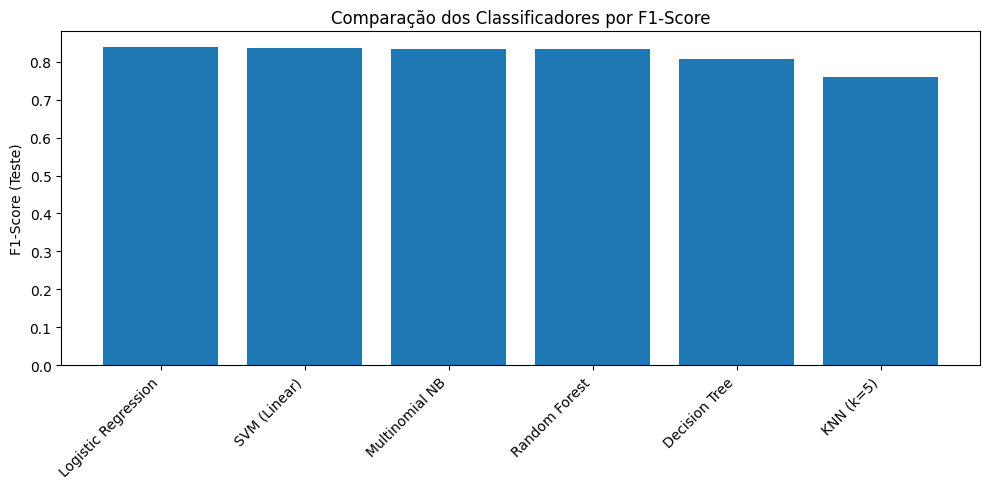

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(comparison_df['Modelo'], comparison_df['F1_Test'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('F1-Score (Teste)')
plt.title('Comparação dos Classificadores por F1-Score')
plt.tight_layout()
plt.show()


## 11.6 Observação sobre a Escolha Final

A escolha do melhor modelo não deve basear-se apenas na accuracy. Em tarefas de análise de sentimentos, o **F1-score** é particularmente importante porque equilibra precision e recall, sendo mais informativo para avaliar o comportamento global do classificador.

Nesta comparação, a **Logistic Regression** foi selecionada como melhor modelo clássico, com **accuracy de 0.8352**, **precision de 0.8655**, **recall de 0.8120**, **F1-score de 0.8379** e **Kappa de 0.6707**.

Este resultado é coerente com a natureza dos dados: modelos lineares tendem a funcionar bem em texto representado por TF-IDF, uma vez que conseguem aprender pesos discriminativos para palavras e expressões associadas a cada classe.

O **SVM Linear** e o **Multinomial Naive Bayes** apresentaram resultados muito próximos, o que mostra que não existe uma diferença extrema entre os melhores classificadores clássicos. Ainda assim, no conjunto de teste final, a Logistic Regression obteve o melhor equilíbrio entre precision e recall, justificando a sua escolha como referência clássica para comparação com o DistilBERT.

## 11.7 Experiência de Originalidade: TF-IDF com N-grams

Como elemento adicional de inovação, testa-se uma representação alternativa com **unigramas e bigramas**. A utilização de bigramas permite capturar pequenas expressões compostas, como *not good*, *very happy* ou *feel bad*, que podem ser relevantes para análise de sentimentos e que se perdem quando se consideram apenas palavras isoladas.


In [ ]:
from sklearn.pipeline import Pipeline

ngram_experiments = {
    'TF-IDF unigramas + Logistic Regression': Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 1))),
        ('clf', LogisticRegression(max_iter=2000, random_state=0))
    ]),
    'TF-IDF unigramas+bigramas + Logistic Regression': Pipeline([
        ('tfidf', TfidfVectorizer(max_features=8000, ngram_range=(1, 2))),
        ('clf', LogisticRegression(max_iter=2000, random_state=0))
    ])
}

# Divisao sobre o texto pre-processado NAO balanceado (sem leakage)
text_tr_ng, text_te_ng, y_tr_ng, y_te_ng = train_test_split(
    review_df['text_preprocessed'],
    review_df[TARGET_COL],
    test_size=0.30,
    random_state=0,
    stratify=review_df[TARGET_COL]
)

# Oversampling aplicado APENAS ao treino
ros_ng = RandomOverSampler(random_state=42)
tr_ng_bal, y_tr_ng_bal = ros_ng.fit_resample(text_tr_ng.to_frame(name='text_preprocessed'), y_tr_ng)

ngram_results = []
for exp_name, pipe in ngram_experiments.items():
    pipe.fit(tr_ng_bal['text_preprocessed'], y_tr_ng_bal)
    pred = pipe.predict(text_te_ng)
    ngram_results.append({
        'Experiência': exp_name,
        'Accuracy': accuracy_score(y_te_ng, pred),
        'Precision': precision_score(y_te_ng, pred, pos_label='positive', zero_division=0),
        'Recall': recall_score(y_te_ng, pred, pos_label='positive', zero_division=0),
        'F1-Score': f1_score(y_te_ng, pred, pos_label='positive', zero_division=0),
        'Kappa': cohen_kappa_score(y_te_ng, pred)
    })

ngram_results_df = pd.DataFrame(ngram_results).sort_values(by='F1-Score', ascending=False)
display(ngram_results_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}',
    'Kappa': '{:.4f}'
}))

,Experiência,Accuracy,Precision,Recall,F1-Score,Kappa
1,TF-IDF unigramas+bigramas + Logistic Regression,0.8364,0.8661,0.8140,0.8392,0.6731
0,TF-IDF unigramas + Logistic Regression,0.8344,0.8686,0.8062,0.8363,0.6692


### Interpretação da experiência com N-grams

A experiência com n-grams foi incluída como elemento adicional de originalidade, permitindo testar se pares de palavras melhoram a representação do texto face aos unigramas isolados.

Em análise de sentimentos, expressões compostas podem ser importantes porque o significado emocional nem sempre está numa palavra isolada. Por exemplo, expressões como **good morning**, **do not like**, **miss you** ou **happy mothers** podem transmitir informação diferente daquela que seria captada por palavras separadas.

Assim, esta experiência permite avaliar se a inclusão de bigramas acrescenta valor preditivo ao modelo ou se aumenta apenas a dimensionalidade sem ganhos relevantes.


## 11.8 Otimização de Hiperparâmetros (GridSearchCV)

Como passo final da comparação de classificadores, aplica-se uma otimização sistemática de hiperparâmetros aos dois modelos lineares/probabilísticos mais competitivos — o **Multinomial Naive Bayes** (parâmetro de suavização `alpha`) e a **Logistic Regression** (parâmetro de regularização `C`). A pesquisa é feita com `GridSearchCV`, usando validação cruzada e `f1_macro` como métrica de otimização, de forma a confirmar se um ajuste fino dos hiperparâmetros melhora o desempenho face às configurações por omissão usadas na comparação anterior.

Os resultados indicam que o melhor ajuste da Logistic Regression foi obtido com `C = 5.0`, alcançando **F1 de teste de 0.8348**. No entanto, este valor não supera o desempenho da Logistic Regression na configuração base apresentada na tabela comparativa (**F1-score de 0.8379**). O Multinomial Naive Bayes manteve o melhor parâmetro `alpha = 1.0`, com **F1 de teste de 0.8327**.

Assim, a otimização confirma que os modelos já se encontravam próximos do seu melhor desempenho com as configurações iniciais, não trazendo ganhos relevantes face à comparação principal.

In [ ]:
from sklearn.model_selection import GridSearchCV

tuning_experiments = {
    'Multinomial NB': {
        'model': MultinomialNB(),
        'params': {'alpha': [0.1, 0.3, 0.5, 0.7, 1.0]}
    },
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=2000, random_state=0),
        'params': {'C': [0.1, 0.5, 1.0, 2.0, 5.0]}
    }
}

tuning_results = []

for model_name, config in tuning_experiments.items():
    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        scoring='f1_macro',
        cv=3,
        n_jobs=-1
    )
    grid.fit(X_train, y_train)
    tuned_pred = grid.predict(X_test)

    tuning_results.append({
        'Modelo': model_name,
        'Melhores parâmetros': grid.best_params_,
        'Melhor F1 CV': grid.best_score_,
        'Accuracy Teste': accuracy_score(y_test, tuned_pred),
        'Precision Teste': precision_score(y_test, tuned_pred, pos_label='positive', zero_division=0),
        'Recall Teste': recall_score(y_test, tuned_pred, pos_label='positive', zero_division=0),
        'F1 Teste': f1_score(y_test, tuned_pred, pos_label='positive', zero_division=0),
        'Kappa Teste': cohen_kappa_score(y_test, tuned_pred)
    })

tuning_results_df = pd.DataFrame(tuning_results).sort_values(by='F1 Teste', ascending=False)

display(tuning_results_df.style.format({
    'Melhor F1 CV': '{:.4f}',
    'Accuracy Teste': '{:.4f}',
    'Precision Teste': '{:.4f}',
    'Recall Teste': '{:.4f}',
    'F1 Teste': '{:.4f}',
    'Kappa Teste': '{:.4f}'
}))

,Modelo,Melhores parâmetros,Melhor F1 CV,Accuracy Teste,Precision Teste,Recall Teste,F1 Teste,Kappa Teste
1,Logistic Regression,{'C': 5.0},0.8568,0.8309,0.8563,0.8144,0.8348,0.6619
0,Multinomial NB,{'alpha': 1.0},0.8553,0.8285,0.8524,0.8140,0.8327,0.6569


# 12. Aplicação do Melhor Modelo a um Novo Exemplo

Depois de selecionado o melhor classificador com base nos resultados comparativos, o passo seguinte consiste em aplicar esse modelo a um novo comentário ainda não visto.


## 12.1 Funções de Pré-processamento para Novo Comentário


In [ ]:
chat_words_map = {
    "FYI": "for your information",
    "BRB": "be right back",
    "THX": "thanks",
    "AFAIK": "as far as i know",
    "ASAP": "as soon as possible",
    "LOL": "laugh out loud",
    "BTW": "by the way",
    "OMG": "oh my god",
    "IDK": "i do not know"
}

emoticon_map = {
    ":-)": "happy face",
    ":)": "happy face",
    ";-)": "wink face",
    ";)": "wink face",
    ":-(": "sad face",
    ":(": "sad face",
    ":-D": "laughing face",
    ":D": "laughing face"
}

stop_words_set = set(stopwords.words('english'))
valid_words_set = set(word.lower() for word in words.words())
lemmatizer_new = WordNetLemmatizer()

def remove_html_and_urls(text):
    text = BeautifulSoup(str(text), "html.parser").get_text()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    return unescape(text)

def expand_chatwords(text):
    tokens = str(text).split()
    expanded = [chat_words_map.get(tok.upper(), tok) for tok in tokens]
    return ' '.join(expanded)

def expand_emoticons(text):
    for emo, meaning in emoticon_map.items():
        text = text.replace(emo, f" {meaning} ")
    return text

def convert_emojis_to_text(text):
    text = emoji.demojize(str(text), delimiters=(" ", " "))
    text = text.replace("_", " ").replace(":", " ")
    return text

def to_lowercase(text):
    return str(text).lower()

def expand_contractions_text(text):
    return contractions.fix(str(text))

def remove_punctuation(text):
    return str(text).translate(str.maketrans('', '', string.punctuation))

def remove_stopwords_text(text):
    tokens = word_tokenize(str(text))
    filtered = [w for w in tokens if w.lower() not in stop_words_set]
    return ' '.join(filtered)

def keep_valid_words_text(text):
    tokens = word_tokenize(str(text))
    filtered = [w for w in tokens if w.lower() in valid_words_set]
    return ' '.join(filtered)

def lemmatize_text_new(text):
    tokens = word_tokenize(str(text))
    lemmas = [lemmatizer_new.lemmatize(w) for w in tokens]
    return ' '.join(lemmas)

def preprocess_new_text(text):
    text = remove_html_and_urls(text)
    text = expand_chatwords(text)
    text = expand_emoticons(text)
    text = convert_emojis_to_text(text)
    text = to_lowercase(text)
    text = expand_contractions_text(text)
    text = remove_punctuation(text)
    text = remove_stopwords_text(text)
    text = keep_valid_words_text(text)
    text = lemmatize_text_new(text)
    return text


## 12.2 Classificação de Novos Comentários

Depois de treinar e selecionar o melhor modelo tradicional, este é aplicado a um conjunto de comentários novos, criados manualmente e não utilizados no treino.

Foram definidos comentários com diferentes níveis de polaridade: mensagens claramente positivas, mensagens claramente negativas e frases com conteúdo emocional misto. Esta abordagem permite avaliar se o classificador consegue generalizar para novos exemplos e se mantém um comportamento coerente perante comentários mais ambíguos.


In [ ]:
novos_comentarios = [
    "I feel much better today and I am proud of the progress I made.",
    "I am exhausted and I do not know how to keep going anymore.",
    "Today was difficult, but I am trying to stay hopeful.",
    "I feel completely alone and nobody understands what I am going through.",
    "Talking to someone really helped me and made me feel supported.",
    "Everything feels too heavy right now and I cannot stop worrying.",
    "I am grateful for the support I received from my friends today.",
    "I could not sleep all night and my anxiety is getting worse.",
    "Small progress is still progress, and that makes me happy.",
    "I feel lost, tired and overwhelmed, even though I am trying my best.",
    "I finally had a calm day and felt more confident about myself.",
    "I keep pretending I am okay, but inside I feel broken."
]

# Classificação interpretativa dos exemplos apenas para contextualizar a análise.
tipo_exemplo = [
    "positivo",
    "negativo",
    "ambíguo",
    "negativo",
    "positivo",
    "negativo",
    "positivo",
    "negativo",
    "positivo",
    "ambíguo",
    "positivo",
    "negativo"
]

# Aplicar exatamente o mesmo pré-processamento usado no treino
novos_comentarios_pp = [preprocess_new_text(comentario) for comentario in novos_comentarios]

# Converter os comentários para a mesma representação TF-IDF usada pelo modelo final
matriz_novos_comentarios = vectorizer_model.transform(novos_comentarios_pp)

# Gerar previsões com o melhor modelo tradicional selecionado anteriormente
previsoes_novos_comentarios = best_model.predict(matriz_novos_comentarios)

# Calcular probabilidade/confiança quando o modelo permitir
if hasattr(best_model, "predict_proba"):
    probabilidades = best_model.predict_proba(matriz_novos_comentarios)
    confianca = probabilidades.max(axis=1)
else:
    probabilidades = None
    confianca = [np.nan] * len(novos_comentarios)

# Criar tabela final com resultados
resultados_novos_comentarios = pd.DataFrame({
    "Tipo de exemplo": tipo_exemplo,
    "Comentário original": novos_comentarios,
    "Comentário pré-processado": novos_comentarios_pp,
    "Sentimento previsto": previsoes_novos_comentarios,
    "Confiança": confianca
})

print("Melhor modelo usado na classificação dos novos comentários:", best_model_name)
display(resultados_novos_comentarios)


Melhor modelo usado na classificação dos novos comentários: Logistic Regression


,Tipo de exemplo,Comentário original,Comentário pré-processado,Sentimento previsto,Confiança
0,positivo,I feel much better today and I am proud of the...,feel much better today progress made,positive,0.637266
1,negativo,I am exhausted and I do not know how to keep g...,exhausted know keep going,negative,0.864471
2,ambíguo,"Today was difficult, but I am trying to stay h...",today difficult trying stay hopeful,negative,0.798188
3,negativo,I feel completely alone and nobody understands...,feel completely alone nobody going,negative,0.868406
4,positivo,Talking to someone really helped me and made m...,talking someone really made feel,negative,0.771606
5,negativo,Everything feels too heavy right now and I can...,everything heavy right stop worrying,negative,0.801905
6,positivo,I am grateful for the support I received from ...,grateful support received today,negative,0.533372
7,negativo,I could not sleep all night and my anxiety is ...,could sleep night anxiety getting worse,negative,0.828787
8,positivo,"Small progress is still progress, and that mak...",small progress still progress happy,positive,0.831187
9,ambíguo,"I feel lost, tired and overwhelmed, even thoug...",feel lost tired even though trying best,negative,0.919959


### Interpretação da Classificação de Novos Comentários

A aplicação do modelo a novos comentários permite observar o seu comportamento fora do conjunto de treino e teste. Os exemplos positivos incluem expressões associadas a melhoria emocional, gratidão, apoio social e progresso pessoal. Os exemplos negativos incluem referências a exaustão, solidão, ansiedade, preocupação e sobrecarga emocional.

Os comentários classificados como mistos ou ambíguos são particularmente importantes, porque combinam elementos negativos com sinais de tentativa de recuperação ou esperança. Nestes casos, é expectável que o modelo apresente maior dificuldade, uma vez que a polaridade emocional não é totalmente explícita.

Esta etapa reforça a utilidade prática do classificador, demonstrando como o modelo pode ser aplicado a novos textos e gerar automaticamente uma previsão de sentimento. Ao mesmo tempo, evidencia que a interpretação dos resultados deve considerar o contexto linguístico e emocional de cada comentário, especialmente em domínios sensíveis como a saúde mental.


## 12.3 Probabilidades Associadas às Previsões

Quando o modelo selecionado disponibiliza probabilidades, a confiança associada a cada previsão é apresentada na tabela anterior. Valores de confiança mais elevados indicam previsões mais seguras, enquanto valores mais próximos entre classes sugerem maior incerteza do modelo.


In [ ]:
if hasattr(best_model, "predict_proba"):
    probabilidade_por_classe = pd.DataFrame(
        probabilidades,
        columns=[f"Probabilidade_{classe}" for classe in best_model.classes_]
    )

    resultados_com_probabilidades = pd.concat(
        [resultados_novos_comentarios[["Tipo de exemplo", "Comentário original", "Sentimento previsto", "Confiança"]],
         probabilidade_por_classe],
        axis=1
    )

    display(resultados_com_probabilidades)
else:
    print(f"O modelo {best_model_name} não disponibiliza probabilidades com predict_proba().")


,Tipo de exemplo,Comentário original,Sentimento previsto,Confiança,Probabilidade_negative,Probabilidade_positive
0,positivo,I feel much better today and I am proud of the...,positive,0.637266,0.362734,0.637266
1,negativo,I am exhausted and I do not know how to keep g...,negative,0.864471,0.864471,0.135529
2,ambíguo,"Today was difficult, but I am trying to stay h...",negative,0.798188,0.798188,0.201812
3,negativo,I feel completely alone and nobody understands...,negative,0.868406,0.868406,0.131594
4,positivo,Talking to someone really helped me and made m...,negative,0.771606,0.771606,0.228394
5,negativo,Everything feels too heavy right now and I can...,negative,0.801905,0.801905,0.198095
6,positivo,I am grateful for the support I received from ...,negative,0.533372,0.533372,0.466628
7,negativo,I could not sleep all night and my anxiety is ...,negative,0.828787,0.828787,0.171213
8,positivo,"Small progress is still progress, and that mak...",positive,0.831187,0.168813,0.831187
9,ambíguo,"I feel lost, tired and overwhelmed, even thoug...",negative,0.919959,0.919959,0.080041


# 13. Uso de LLM com Fine-Tuning

O enunciado solicita a utilização de LLMs com fine-tuning. Para responder a esse requisito, esta secção apresenta uma abordagem com **DistilBERT**, um modelo Transformer pré-treinado, posteriormente ajustado ao dataset do projeto.

Esta experiência deve ser entendida como uma extensão ao pipeline clássico. Enquanto os modelos anteriores dependem de TF-IDF, o modelo baseado em LLM aprende representações contextuais do texto, considerando a posição e o significado das palavras no contexto da frase.


In [ ]:
# Instalação das bibliotecas necessárias para a experiência com LLM
!pip -q install transformers datasets accelerate evaluate


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.9 MB/s eta 0:00:00


In [ ]:
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed
)
from sklearn.preprocessing import LabelEncoder

print('GPU disponível:', torch.cuda.is_available())

# Reprodutibilidade: fixar a seed para random, numpy e torch (CPU e GPU).
# set_seed e chamado novamente antes de cada modelo, pois a inicializacao da
# cabeca de classificacao (pre_classifier/classifier) ocorre no from_pretrained.
SEED = 42
set_seed(SEED)


GPU disponível: False


## 13.1 Preparação dos Dados para o Modelo Transformer

Para reduzir o custo computacional, é criada uma amostra estratificada do dataset. Esta decisão mantém a proporção das classes e permite demonstrar o fine-tuning de forma prática no Colab.


In [ ]:
llm_df = review_df.copy()
sample_size_per_class = min(800, llm_df[TARGET_COL].value_counts().min())

llm_sample = (
    llm_df
    .groupby(TARGET_COL, group_keys=False)
    .apply(lambda x: x.sample(sample_size_per_class, random_state=42))
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

label_encoder = LabelEncoder()
llm_sample['label'] = label_encoder.fit_transform(llm_sample[TARGET_COL])

train_llm, test_llm = train_test_split(
    llm_sample[[TEXT_COL, 'label']],
    test_size=0.20,
    random_state=42,
    stratify=llm_sample['label']
)

print('Distribuição treino:')
print(train_llm['label'].value_counts())

print('\nDistribuição teste:')
print(test_llm['label'].value_counts())

print('\nMapeamento das classes:')
print(dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))


Distribuição treino:
label
0    640
1    640
Name: count, dtype: int64

Distribuição teste:
label
1    160
0    160
Name: count, dtype: int64

Mapeamento das classes:
{'negative': np.int64(0), 'positive': np.int64(1)}


## 13.2 Tokenização e Fine-Tuning do DistilBERT

O texto é convertido para o formato esperado pelo modelo Transformer através do tokenizer. De seguida, o modelo é ajustado ao problema de classificação binária do projeto.

### Nota sobre reprodutibilidade dos resultados

Os resultados do fine-tuning do DistilBERT podem apresentar pequenas variações entre execuções, mesmo quando o código e os dados se mantêm praticamente iguais. Isto acontece porque o treino de modelos baseados em redes neuronais envolve processos estocásticos, como a inicialização e atualização dos pesos, a ordem dos batches e determinadas operações internas do ambiente de execução.

Além disso, em ambientes como o Google Colab, diferentes sessões podem usar configurações de hardware ou versões de bibliotecas ligeiramente distintas, o que também pode originar pequenas diferenças nas métricas finais. Por esse motivo, variações reduzidas na accuracy, no F1-score ou no Kappa são normais e não invalidam os resultados, desde que a tendência geral se mantenha consistente. Para mitigar esta variabilidade, foi fixada uma **seed** global (`set_seed`) antes da criação de cada modelo e nos `TrainingArguments` (`seed` e `data_seed`). Em CPU, isto torna os resultados praticamente determinísticos; em GPU, algumas operações do CUDA não são totalmente determinísticas, pelo que pequenas variações residuais podem ainda ocorrer.

Neste projeto, a interpretação deve focar-se sobretudo na comparação global entre abordagens: o DistilBERT mantém melhor desempenho global do que o melhor modelo clássico, enquanto a versão com texto original continua a superar a versão com texto pré-processado.


In [ ]:
model_checkpoint = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

def tokenize_function(batch):
    return tokenizer(batch[TEXT_COL], truncation=True, max_length=128)

train_dataset = Dataset.from_pandas(train_llm.reset_index(drop=True))
test_dataset = Dataset.from_pandas(test_llm.reset_index(drop=True))

train_dataset = train_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)

train_dataset = train_dataset.remove_columns([TEXT_COL])
test_dataset = test_dataset.remove_columns([TEXT_COL])
train_dataset.set_format('torch')
test_dataset.set_format('torch')

id2label = {i: label for i, label in enumerate(label_encoder.classes_)}
label2id = {label: i for i, label in id2label.items()}

set_seed(SEED)  # garante inicializacao reprodutivel da cabeca de classificacao
llm_model = AutoModelForSequenceClassification.from_pretrained(
    model_checkpoint,
    num_labels=len(label_encoder.classes_),
    id2label=id2label,
    label2id=label2id
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/1280 [00:00<?, ? examples/s]

Map:   0%|          | 0/320 [00:00<?, ? examples/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
def compute_metrics_llm(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        'accuracy': accuracy_score(labels, predictions),
        'precision': precision_score(labels, predictions, zero_division=0),
        'recall': recall_score(labels, predictions, zero_division=0),
        'f1': f1_score(labels, predictions, zero_division=0),
        'kappa': cohen_kappa_score(labels, predictions)
    }

training_args = TrainingArguments(
    output_dir='./distilbert_sentiment_results',
    seed=SEED,
    data_seed=SEED,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=50,
    save_strategy='no',
    report_to='none'
)

trainer = Trainer(
    model=llm_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics_llm
)

import datasets.config

datasets.config.TORCHVISION_AVAILABLE = False
trainer.train()
llm_eval_results = trainer.evaluate()
llm_eval_results


Step,Training Loss
50,0.624849
100,0.315323
150,0.244367


{'eval_loss': 0.2637156546115875,
 'eval_accuracy': 0.9,
 'eval_precision': 0.9637681159420289,
 'eval_recall': 0.83125,
 'eval_f1': 0.8926174496644296,
 'eval_kappa': 0.8,
 'eval_runtime': 21.2744,
 'eval_samples_per_second': 15.042,
 'eval_steps_per_second': 0.94,
 'epoch': 2.0}

## 13.3 Comparação do DistilBERT com e sem Pré-processamento

Para avaliar o impacto do pré-processamento na abordagem baseada em Transformer, o DistilBERT é testado em duas condições experimentais:

- **sem pré-processamento**, utilizando o texto original;
- **com pré-processamento**, utilizando a coluna `text_preprocessed` resultante do pipeline de limpeza textual.

Esta comparação é relevante porque os modelos de linguagem pré-treinados foram originalmente treinados com texto em linguagem natural. Assim, um pré-processamento demasiado agressivo pode remover informação contextual importante, como negações, intensificadores emocionais e estrutura frásica. Por outro lado, a versão pré-processada pode reduzir ruído e tornar o texto mais direto para a classificação.


In [ ]:
LLM_TEXT_PREPROCESSED_COL = 'text_preprocessed'

llm_sample_preprocessed = llm_sample[[LLM_TEXT_PREPROCESSED_COL, 'label']].copy()
llm_sample_preprocessed[LLM_TEXT_PREPROCESSED_COL] = (
    llm_sample_preprocessed[LLM_TEXT_PREPROCESSED_COL]
    .fillna('')
    .astype(str)
    .str.strip()
)

# Remover eventuais textos vazios após o pré-processamento
llm_sample_preprocessed = llm_sample_preprocessed[
    llm_sample_preprocessed[LLM_TEXT_PREPROCESSED_COL] != ''
].reset_index(drop=True)

train_llm_preprocessed, test_llm_preprocessed = train_test_split(
    llm_sample_preprocessed[[LLM_TEXT_PREPROCESSED_COL, 'label']],
    test_size=0.20,
    random_state=42,
    stratify=llm_sample_preprocessed['label']
)

print('Distribuição treino - texto pré-processado:')
print(train_llm_preprocessed['label'].value_counts())

print('Distribuição teste - texto pré-processado:')
print(test_llm_preprocessed['label'].value_counts())


Distribuição treino - texto pré-processado:
label
1    635
0    631
Name: count, dtype: int64
Distribuição teste - texto pré-processado:
label
1    159
0    158
Name: count, dtype: int64


In [ ]:
def tokenize_function_preprocessed(batch):
    return tokenizer(batch[LLM_TEXT_PREPROCESSED_COL], truncation=True, max_length=128)

train_dataset_preprocessed = Dataset.from_pandas(train_llm_preprocessed.reset_index(drop=True))
test_dataset_preprocessed = Dataset.from_pandas(test_llm_preprocessed.reset_index(drop=True))

train_dataset_preprocessed = train_dataset_preprocessed.map(tokenize_function_preprocessed, batched=True)
test_dataset_preprocessed = test_dataset_preprocessed.map(tokenize_function_preprocessed, batched=True)

train_dataset_preprocessed = train_dataset_preprocessed.remove_columns([LLM_TEXT_PREPROCESSED_COL])
test_dataset_preprocessed = test_dataset_preprocessed.remove_columns([LLM_TEXT_PREPROCESSED_COL])
train_dataset_preprocessed.set_format('torch')
test_dataset_preprocessed.set_format('torch')

set_seed(SEED)  # mesma seed para uma comparacao justa entre as duas variantes
llm_model_preprocessed = AutoModelForSequenceClassification.from_pretrained(
    model_checkpoint,
    num_labels=len(label_encoder.classes_),
    id2label=id2label,
    label2id=label2id
)

training_args_preprocessed = TrainingArguments(
    output_dir='./distilbert_sentiment_results_preprocessed',
    seed=SEED,
    data_seed=SEED,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=50,
    save_strategy='no',
    report_to='none'
)

trainer_preprocessed = Trainer(
    model=llm_model_preprocessed,
    args=training_args_preprocessed,
    train_dataset=train_dataset_preprocessed,
    eval_dataset=test_dataset_preprocessed,
    data_collator=data_collator,
    compute_metrics=compute_metrics_llm
)

trainer_preprocessed.train()
llm_eval_results_preprocessed = trainer_preprocessed.evaluate()
llm_eval_results_preprocessed


Map:   0%|          | 0/1266 [00:00<?, ? examples/s]

Map:   0%|          | 0/317 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.651734
100,0.437364
150,0.338019


{'eval_loss': 0.32220590114593506,
 'eval_accuracy': 0.8706624605678234,
 'eval_precision': 0.8881578947368421,
 'eval_recall': 0.8490566037735849,
 'eval_f1': 0.8681672025723473,
 'eval_kappa': 0.7413583809277426,
 'eval_runtime': 8.9842,
 'eval_samples_per_second': 35.284,
 'eval_steps_per_second': 2.226,
 'epoch': 2.0}


### Tabela Comparativa dos LLMs

A tabela seguinte consolida os resultados obtidos pelo DistilBERT nas duas versões testadas. Esta análise permite verificar empiricamente se o modelo beneficia mais do texto original ou do texto pré-processado.

In [ ]:
llm_comparison_df = pd.DataFrame([
    {
        'LLM': 'DistilBERT fine-tuned',
        'Tipo de Texto': 'Sem pré-processamento (texto original)',
        'Accuracy': llm_eval_results.get('eval_accuracy'),
        'Precision': llm_eval_results.get('eval_precision'),
        'Recall': llm_eval_results.get('eval_recall'),
        'F1-Score': llm_eval_results.get('eval_f1'),
        'Kappa': llm_eval_results.get('eval_kappa')
    },
    {
        'LLM': 'DistilBERT fine-tuned',
        'Tipo de Texto': 'Com pré-processamento (texto limpo)',
        'Accuracy': llm_eval_results_preprocessed.get('eval_accuracy'),
        'Precision': llm_eval_results_preprocessed.get('eval_precision'),
        'Recall': llm_eval_results_preprocessed.get('eval_recall'),
        'F1-Score': llm_eval_results_preprocessed.get('eval_f1'),
        'Kappa': llm_eval_results_preprocessed.get('eval_kappa')
    }
])

display(llm_comparison_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}',
    'Kappa': '{:.4f}'
}))

,LLM,Tipo de Texto,Accuracy,Precision,Recall,F1-Score,Kappa
0,DistilBERT fine-tuned,Sem pré-processamento (texto original),0.9000,0.9638,0.8313,0.8926,0.8000
1,DistilBERT fine-tuned,Com pré-processamento (texto limpo),0.8707,0.8882,0.8491,0.8682,0.7414


### Resultados da Comparação do LLM com e sem Pré-processamento

A comparação entre as duas variantes do DistilBERT evidencia que o modelo apresenta melhor desempenho quando utiliza o texto original, sem aplicação do pré-processamento linguístico completo.

Na variante sem pré-processamento, o DistilBERT obteve **accuracy de 0.9000**, **precision de 0.9638**, **recall de 0.8313**, **F1-score de 0.8926** e **Kappa de 0.8000**. Já a versão com texto pré-processado alcançou **accuracy de 0.8707**, **precision de 0.8882**, **recall de 0.8491**, **F1-score de 0.8682** e **Kappa de 0.7414**.

Apesar de a versão pré-processada apresentar um recall ligeiramente superior, a versão com texto original é claramente melhor em accuracy, precision, F1-score e Kappa. Isto sugere que o texto original preserva informação linguística relevante para modelos Transformer, como pontuação, estrutura frásica, negações, intensidade emocional e expressões informais.

O valor de precision é particularmente elevado na versão sem pré-processamento, atingindo **0.9638**. Isto indica que, quando o modelo classifica um comentário como positivo, apresenta uma fiabilidade muito elevada nessa previsão.

Além disso, o coeficiente Kappa é superior na versão com texto original (**0.8000**) face à versão com texto pré-processado (**0.7414**), reforçando que a preservação do texto original contribuiu para uma maior concordância entre as previsões do modelo e os valores reais.

Desta forma, conclui-se que, no caso do DistilBERT, a utilização do texto original é mais adequada do que a utilização do texto pré-processado. Este resultado está alinhado com a natureza dos modelos de linguagem pré-treinados, que foram desenvolvidos para interpretar texto em contexto e podem beneficiar da preservação da estrutura linguística original.

## 13.4 Comparação entre Modelo Clássico e LLM

Após o fine-tuning, o desempenho do **DistilBERT** foi comparado com o melhor modelo clássico identificado anteriormente, a **Logistic Regression**.

Esta comparação é importante porque permite avaliar se o ganho de desempenho obtido por um modelo Transformer compensa o maior custo computacional e a maior complexidade de implementação.

In [ ]:
llm_summary = pd.DataFrame([{
    'Modelo': 'DistilBERT fine-tuned',
    'Accuracy': llm_eval_results.get('eval_accuracy'),
    'Precision': llm_eval_results.get('eval_precision'),
    'Recall': llm_eval_results.get('eval_recall'),
    'F1-Score': llm_eval_results.get('eval_f1'),
    'Kappa': llm_eval_results.get('eval_kappa')
}])

classic_best_summary = pd.DataFrame([{
    'Modelo': best_model_name,
    'Accuracy': comparison_df.loc[0, 'Accuracy_Test'],
    'Precision': comparison_df.loc[0, 'Precision_Test'],
    'Recall': comparison_df.loc[0, 'Recall_Test'],
    'F1-Score': comparison_df.loc[0, 'F1_Test'],
    'Kappa': comparison_df.loc[0, 'Kappa_Test']
}])

final_model_comparison = pd.concat([classic_best_summary, llm_summary], ignore_index=True)
display(final_model_comparison.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}',
    'Kappa': '{:.4f}'
}))


,Modelo,Accuracy,Precision,Recall,F1-Score,Kappa
0,Logistic Regression,0.8352,0.8655,0.8120,0.8379,0.6707
1,DistilBERT fine-tuned,0.9000,0.9638,0.8313,0.8926,0.8000


### Resultado da Comparação entre Modelo Tradicional e DistilBERT

A comparação entre o melhor modelo clássico e o DistilBERT permite avaliar o impacto de uma abordagem baseada em modelos de linguagem pré-treinados.

A **Logistic Regression** apresenta um desempenho sólido, com **accuracy de 0.8352**, **precision de 0.8655**, **recall de 0.8120**, **F1-score de 0.8379** e **Kappa de 0.6707**. Estes resultados demonstram que uma representação TF-IDF combinada com um classificador linear pode ser bastante eficaz em análise de sentimentos.

No entanto, o **DistilBERT** alcança o melhor desempenho global, com **accuracy de 0.9000**, **precision de 0.9638**, **recall de 0.8313**, **F1-score de 0.8926** e **Kappa de 0.8000**. Estes valores indicam uma melhoria face ao modelo clássico, sobretudo ao nível da precision, do F1-score e da concordância global medida pelo Kappa.

Esta diferença pode ser explicada pela capacidade dos modelos Transformer em representar o significado das palavras de forma contextual. Ao contrário do TF-IDF, que trata os termos de forma mais independente, o DistilBERT consegue capturar relações semânticas entre palavras e expressões, o que é particularmente útil em textos informais e emocionalmente ambíguos.

Apesar do desempenho superior, a abordagem com LLM implica maior custo computacional e maior complexidade de treino. Assim, a escolha entre modelos tradicionais e LLMs deve considerar não apenas a performance, mas também os recursos disponíveis e o contexto de aplicação. Neste caso, o DistilBERT revelou-se a melhor opção em termos de desempenho, enquanto a Logistic Regression se manteve uma alternativa simples, rápida e competitiva.

## 13.5 Comparação das Previsões em Novos Comentários: Modelo Clássico vs DistilBERT

Para complementar a aplicação prática do modelo, os mesmos comentários novos são também classificados pelo DistilBERT. Esta comparação permite observar se o modelo baseado em Transformer interpreta melhor frases ambíguas ou emocionalmente subtis.

Enquanto o modelo clássico usa o texto pré-processado e representado por TF-IDF, o DistilBERT recebe o texto original e utiliza representações contextuais aprendidas durante o fine-tuning.

In [ ]:
def predict_with_distilbert(texts, trainer, tokenizer, id2label, max_length=128):
    model = trainer.model
    model.eval()
    device = model.device

    inputs = tokenizer(
        list(texts),
        truncation=True,
        padding=True,
        max_length=max_length,
        return_tensors='pt'
    )
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        logits = model(**inputs).logits
        probabilities = torch.softmax(logits, dim=-1).cpu().numpy()

    pred_ids = probabilities.argmax(axis=1)
    pred_labels = [id2label[int(i)] for i in pred_ids]
    confidence = probabilities.max(axis=1)

    return pred_labels, confidence

# Previsões do DistilBERT nos mesmos comentários usados no modelo clássico
distilbert_pred_labels, distilbert_confidence = predict_with_distilbert(
    novos_comentarios,
    trainer,
    tokenizer,
    id2label
)

comparacao_novos_comentarios = resultados_novos_comentarios[[
    'Tipo de exemplo',
    'Comentário original',
    'Sentimento previsto',
    'Confiança'
]].rename(columns={
    'Sentimento previsto': f'Previsão {best_model_name}',
    'Confiança': f'Confiança {best_model_name}'
})

comparacao_novos_comentarios['Previsão DistilBERT'] = distilbert_pred_labels
comparacao_novos_comentarios['Confiança DistilBERT'] = distilbert_confidence
comparacao_novos_comentarios['Os modelos concordam?'] = (
    comparacao_novos_comentarios[f'Previsão {best_model_name}']
    == comparacao_novos_comentarios['Previsão DistilBERT']
)

display(comparacao_novos_comentarios)

,Tipo de exemplo,Comentário original,Previsão Logistic Regression,Confiança Logistic Regression,Previsão DistilBERT,Confiança DistilBERT,Os modelos concordam?
0,positivo,I feel much better today and I am proud of the...,positive,0.637266,positive,0.953743,True
1,negativo,I am exhausted and I do not know how to keep g...,negative,0.864471,negative,0.950241,True
2,ambíguo,"Today was difficult, but I am trying to stay h...",negative,0.798188,negative,0.910774,True
3,negativo,I feel completely alone and nobody understands...,negative,0.868406,negative,0.947336,True
4,positivo,Talking to someone really helped me and made m...,negative,0.771606,positive,0.869474,False
5,negativo,Everything feels too heavy right now and I can...,negative,0.801905,negative,0.953643,True
6,positivo,I am grateful for the support I received from ...,negative,0.533372,positive,0.955847,False
7,negativo,I could not sleep all night and my anxiety is ...,negative,0.828787,negative,0.947767,True
8,positivo,"Small progress is still progress, and that mak...",positive,0.831187,positive,0.956210,True
9,ambíguo,"I feel lost, tired and overwhelmed, even thoug...",negative,0.919959,negative,0.953216,True


### Síntese da Classificação de Novos Comentários

A comparação entre a Logistic Regression e o DistilBERT mostra uma elevada concordância entre os modelos, uma vez que ambos produziram a mesma previsão em **10 dos 12 comentários** analisados.

As principais diferenças ocorrem nos comentários “Talking to someone really helped me and made me feel supported.” e “I am grateful for the support I received from my friends today.”. Em ambos os casos, a Logistic Regression classificou os comentários como negativos, enquanto o DistilBERT os classificou como positivos.

Esta diferença evidencia a maior capacidade do modelo Transformer em interpretar o contexto global da frase. No primeiro caso, o DistilBERT reconhece que a expressão “helped me” e a ideia de apoio emocional apontam para uma evolução positiva. No segundo caso, identifica corretamente a gratidão e o suporte social como sinais de sentimento positivo.

Os comentários ambíguos foram classificados como negativos por ambos os modelos, sugerindo que expressões associadas a cansaço, sobrecarga ou dificuldade emocional tendem a influenciar fortemente a previsão.

De forma geral, esta análise confirma que o DistilBERT apresenta uma interpretação contextual mais robusta, enquanto a Logistic Regression continua a ser uma alternativa simples e competitiva para classificação de sentimentos.

## 13.6 Análise Complementar dos Resultados

Para além da comparação global entre modelos, foi realizada uma análise mais detalhada ao desempenho do **DistilBERT fine-tuned**, uma vez que este apresentou os melhores resultados globais.

A análise inclui a matriz de confusão, o relatório de classificação e a identificação dos principais tipos de erro. Esta etapa é importante porque permite compreender não apenas quanto o modelo acerta, mas também **onde e como erra**.

No conjunto de teste do DistilBERT, foram identificados **32 erros**, correspondentes a uma taxa de erro de aproximadamente **10.00%**. A análise dos erros mostra que ainda existem casos em que a polaridade real do comentário não é corretamente captada pelo modelo.

Este resultado deve ser interpretado em conjunto com as métricas globais. Embora o DistilBERT apresente o melhor desempenho geral, continua a ter dificuldades em comentários curtos, ambíguos ou emocionalmente subtis, nos quais a classificação depende de contexto implícito, ironia, intensidade emocional ou expressões pouco frequentes.

Além disso, pequenas variações no número de erros entre execuções são esperadas em modelos Transformer, uma vez que o processo de fine-tuning envolve componentes estocásticas. Assim, o mais relevante é verificar se a tendência global dos resultados se mantém estável: o DistilBERT continua a superar o modelo clássico e a versão com texto original continua a obter melhor desempenho do que a versão com texto pré-processado.

<Figure size 600x500 with 0 Axes>

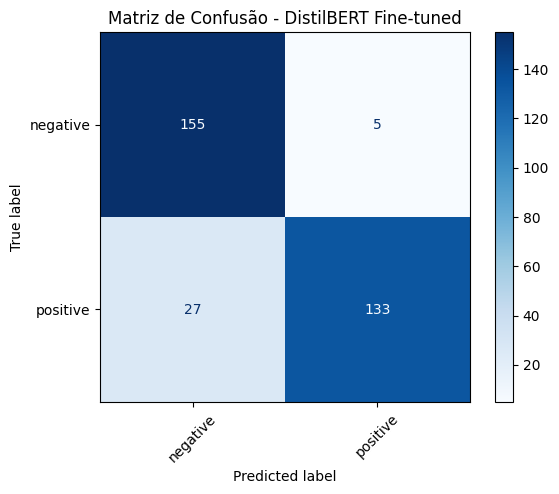

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Previsões do modelo
predictions_output = trainer.predict(test_dataset)

# Extract true labels (y_true) and predicted labels (y_pred_bert)
y_true = predictions_output.label_ids
y_pred_logits = predictions_output.predictions
y_pred_bert = np.argmax(y_pred_logits, axis=-1)

# Mapeamento das classes: {'negative': np.int64(0), 'positive': np.int64(1)}
class_names = list(label_encoder.classes_)

cm = confusion_matrix(y_true, y_pred_bert)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

plt.figure(figsize=(6, 5))
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - DistilBERT Fine-tuned")
plt.xticks(rotation=45)
plt.show()


In [ ]:
# Criar dataframe com previsões
error_analysis_df = test_llm.copy().reset_index(drop=True)

error_analysis_df["real_label"] = y_true
error_analysis_df["predicted_label"] = y_pred_bert

error_analysis_df["real_sentiment"] = label_encoder.inverse_transform(error_analysis_df["real_label"])
error_analysis_df["predicted_sentiment"] = label_encoder.inverse_transform(error_analysis_df["predicted_label"])

# Filtrar apenas erros
errors_df = error_analysis_df[
    error_analysis_df["real_label"] != error_analysis_df["predicted_label"]
]

print(f"Número total de erros: {len(errors_df)}")
print(f"Percentagem de erros: {len(errors_df) / len(error_analysis_df) * 100:.2f}%")

errors_df[[TEXT_COL, "real_sentiment", "predicted_sentiment"]].head(10)


Número total de erros: 32
Percentagem de erros: 10.00%


,text,real_sentiment,predicted_sentiment
7,Manchester was wayyyyy to busy! so warm today...,negative,positive
13,let me know how it goes I`m praying. Ummmph. ...,positive,negative
27,_lottie Not one of my favourite pastimes This...,positive,negative
48,I gave up cable in these tough economic time...,positive,negative
68,i looooove me some star trek. runs in the family,positive,negative
71,Can`t wait for the next twitter.,positive,negative
87,gettin ready to put on a show ugh i really ho...,negative,positive
89,"Of course. I`d send it to you, but I don`t th...",positive,negative
95,"is sore from weight lifting However, it`s the...",positive,negative
117,i seriously neeed to study,positive,negative


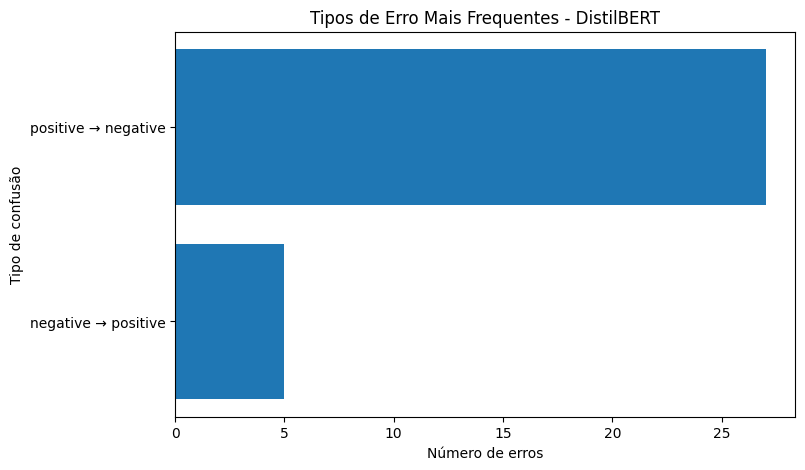

In [ ]:
import matplotlib.pyplot as plt

# Criar a tabela de resumo dos erros
error_summary = errors_df.groupby(['real_sentiment', 'predicted_sentiment']).size().reset_index(name='n_errors')

error_summary["confusion_type"] = (
    error_summary["real_sentiment"].astype(str)
    + " → "
    + error_summary["predicted_sentiment"].astype(str)
)

# Order by number of errors
error_summary = error_summary.sort_values(by='n_errors', ascending=False)

plt.figure(figsize=(8, 5))
plt.barh(error_summary["confusion_type"], error_summary["n_errors"])
plt.xlabel("Número de erros")
plt.ylabel("Tipo de confusão")
plt.title("Tipos de Erro Mais Frequentes - DistilBERT")
plt.gca().invert_yaxis()
plt.show()


# 14. Explainable AI com SHAP

Esta secção acrescenta uma componente de **eXplainable AI (XAI)** ao projeto, seguindo a lógica apresentada na matéria da unidade curricular: não basta avaliar o modelo através de métricas como accuracy, precision, recall ou F1-score; também é importante compreender **porque motivo** o modelo atribui determinada classificação.

Em problemas de Text Mining, a explicabilidade é especialmente relevante porque as decisões do classificador dependem de palavras ou expressões presentes nos comentários. Assim, foi utilizada a técnica **SHAP (SHapley Additive exPlanations)** para analisar a contribuição das palavras/features TF-IDF nas previsões do modelo.

A análise foi dividida em dois níveis:

- **Explicabilidade global**: identificação das palavras que mais influenciam o comportamento geral do modelo.
- **Explicabilidade local**: explicação da previsão de um comentário específico, mostrando quais as palavras que contribuíram positiva ou negativamente para a classificação.


## 14.1 Instalação e carregamento do SHAP

Nesta célula é carregada a biblioteca `shap`, necessária para a análise XAI. O carregamento é feito de forma controlada: se a biblioteca já estiver disponível no ambiente, é apenas importada; caso contrário, é instalada e depois carregada. Os restantes módulos usados nesta secção já tinham sido utilizados anteriormente no notebook.

In [ ]:
# Instalação e carregamento do SHAP
try:
    import shap
except ImportError:
    !pip -q install shap
    import shap

print("SHAP carregado com sucesso.")

SHAP carregado com sucesso.


## 14.2 Modelo utilizado para a explicabilidade

Embora o notebook compare vários classificadores e selecione automaticamente o melhor modelo clássico, a análise com SHAP é aplicada a um modelo linear treinado com a mesma matriz TF-IDF. Esta escolha torna a interpretação mais direta, porque permite associar cada valor SHAP a uma palavra/feature concreta.

Assim, a explicabilidade não substitui a avaliação quantitativa dos modelos; funciona como uma análise complementar para compreender que termos têm maior impacto na classificação de sentimento.


In [ ]:
# Modelo auxiliar para Explainable AI
# Usa a mesma representação TF-IDF e a mesma divisão treino/teste já criadas anteriormente.
xai_model = LogisticRegression(max_iter=2000, random_state=0)
xai_model.fit(X_train, y_train)

xai_pred = xai_model.predict(X_test)

print("Modelo usado na secção XAI:", xai_model)
print("Accuracy no conjunto de teste:", round(accuracy_score(y_test, xai_pred), 4))
print("F1-score no conjunto de teste:", round(f1_score(y_test, xai_pred, pos_label='positive', zero_division=0), 4))
print("Classes do modelo:", list(xai_model.classes_))


Modelo usado na secção XAI: LogisticRegression(max_iter=2000, random_state=0)
Accuracy no conjunto de teste: 0.8352
F1-score no conjunto de teste: 0.8379
Classes do modelo: ['negative', 'positive']


## 14.3 Cálculo dos valores SHAP

Os valores SHAP são calculados sobre uma amostra do conjunto de teste para reduzir o tempo de processamento. Cada valor representa a contribuição de uma feature para aproximar ou afastar a previsão de uma determinada classe.

Como o problema é binário, a interpretação é feita em relação à classe `positive`. Valores SHAP positivos indicam contribuição para a classificação positiva, enquanto valores negativos indicam contribuição no sentido oposto.


In [ ]:
# Obter nomes das features TF-IDF
feature_names = vectorizer_model.get_feature_names_out()

# Amostra para explicabilidade global, evitando processamento excessivo no Colab
xai_sample_size = min(200, X_test.shape[0])
X_test_xai_sample = X_test[:xai_sample_size]

# Criar explainer SHAP para modelo linear
explainer = shap.LinearExplainer(xai_model, X_train)
shap_values_sample = explainer(X_test_xai_sample)

# Função auxiliar para obter a matriz de valores SHAP da classe positiva
def get_shap_values_for_class(shap_explanation, model, target_class='positive'):
    values = shap_explanation.values
    classes = list(model.classes_)
    class_index = classes.index(target_class) if target_class in classes else min(1, len(classes) - 1)

    if isinstance(values, list):
        return values[class_index], class_index

    values = np.asarray(values)
    if values.ndim == 3:
        return values[:, :, class_index], class_index

    return values, class_index

shap_values_positive, positive_class_index = get_shap_values_for_class(
    shap_values_sample,
    xai_model,
    target_class='positive'
)

print("Valores SHAP calculados para a classe:", xai_model.classes_[positive_class_index])
print("Dimensão da matriz SHAP:", shap_values_positive.shape)


Valores SHAP calculados para a classe: positive
Dimensão da matriz SHAP: (200, 1000)


## 14.4 Explicabilidade global: palavras mais importantes

A explicabilidade global permite perceber quais são as palavras/features que mais influenciam o comportamento geral do modelo. Para isso, é calculado o valor médio absoluto de SHAP para cada feature.

Quanto maior for o valor médio absoluto de SHAP, maior é a relevância dessa palavra no processo de decisão do classificador.


In [ ]:
# Importância global das features com base no valor médio absoluto de SHAP
mean_abs_shap = np.abs(shap_values_positive).mean(axis=0)
mean_shap = shap_values_positive.mean(axis=0)

shap_importance_df = pd.DataFrame({
    'feature': feature_names,
    'mean_abs_shap': mean_abs_shap,
    'mean_shap': mean_shap
})

shap_importance_df['direcao_media'] = np.where(
    shap_importance_df['mean_shap'] >= 0,
    'contribui mais para positive',
    'contribui mais para negative'
)

shap_importance_df = shap_importance_df.sort_values(
    by='mean_abs_shap',
    ascending=False
).reset_index(drop=True)

print("Top 20 palavras/features mais importantes segundo SHAP:")
display(shap_importance_df.head(20))


Top 20 palavras/features mais importantes segundo SHAP:


,feature,mean_abs_shap,mean_shap,direcao_media
0,good,0.196368,-0.014809,contribui mais para negative
1,great,0.191885,-0.064169,contribui mais para negative
2,thanks,0.173495,0.005374,contribui mais para positive
3,love,0.148909,0.008895,contribui mais para positive
4,hate,0.140909,0.083975,contribui mais para positive
5,sad,0.122437,0.034036,contribui mais para positive
6,sorry,0.114838,0.046764,contribui mais para positive
7,thank,0.110342,-0.091832,contribui mais para negative
8,happy,0.103012,-0.057294,contribui mais para negative
9,hope,0.093000,0.002323,contribui mais para positive


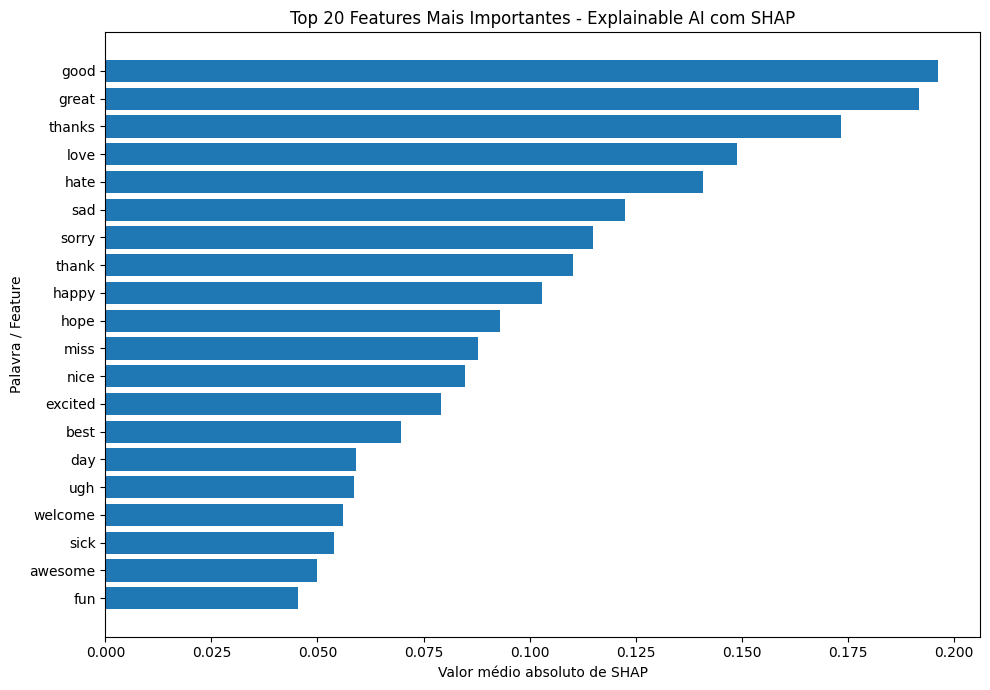

In [ ]:
# Visualização das palavras/features mais importantes
TOP_N = 20
top_features_plot = shap_importance_df.head(TOP_N).sort_values('mean_abs_shap', ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(top_features_plot['feature'], top_features_plot['mean_abs_shap'])
plt.xlabel('Valor médio absoluto de SHAP')
plt.ylabel('Palavra / Feature')
plt.title('Top 20 Features Mais Importantes - Explainable AI com SHAP')
plt.tight_layout()
plt.show()


### Interpretação da explicabilidade global

A tabela e o gráfico anteriores mostram as palavras com maior influência média nas decisões do modelo. Estas palavras são aquelas que, de forma mais consistente, alteram a previsão do classificador.

Em análise de sentimentos, espera-se que palavras associadas a bem-estar, apoio, progresso ou melhoria tenham uma contribuição positiva para a classe `positive`. Por outro lado, termos associados a sofrimento, exaustão, ansiedade, solidão ou dificuldade emocional tendem a contribuir para a classe `negative`.

Esta análise permite verificar se o modelo está a tomar decisões com base em padrões linguísticos coerentes com o domínio do problema, em vez de depender apenas de métricas agregadas de desempenho.


## 14.5 Explicabilidade local: explicação de um comentário individual

A explicabilidade local permite analisar uma previsão específica. Nesta etapa, é selecionado um dos novos comentários classificados anteriormente e são identificadas as palavras que mais contribuíram para a decisão do modelo.

Esta análise aproxima-se do exemplo dado na matéria, onde uma previsão individual é explicada através das palavras com impacto positivo ou negativo.


In [ ]:
# Escolher um comentário novo para explicação local
# Pode alterar este índice para analisar outros exemplos da lista novos_comentarios.
xai_local_index = 0

comentario_original = novos_comentarios[xai_local_index]
comentario_preprocessado = novos_comentarios_pp[xai_local_index]
matriz_comentario = matriz_novos_comentarios[xai_local_index]

predicao_xai = xai_model.predict(matriz_comentario)[0]

if hasattr(xai_model, 'predict_proba'):
    probabilidade_xai = xai_model.predict_proba(matriz_comentario).max()
else:
    probabilidade_xai = np.nan

print("Comentário original:")
print(comentario_original)
print("\nComentário pré-processado:")
print(comentario_preprocessado)
print("\nPrevisão do modelo XAI:", predicao_xai)
print("Confiança:", round(probabilidade_xai, 4) if not np.isnan(probabilidade_xai) else "não disponível")

Comentário original:
I feel much better today and I am proud of the progress I made.

Comentário pré-processado:
feel much better today progress made

Previsão do modelo XAI: positive
Confiança: 0.6373


In [ ]:
# Calcular SHAP para o comentário selecionado
shap_values_local = explainer(matriz_comentario)
local_values, _ = get_shap_values_for_class(
    shap_values_local,
    xai_model,
    target_class='positive'
)

# Garantir vetor unidimensional
local_values = np.asarray(local_values).reshape(-1)

# Considerar apenas features presentes no comentário
nonzero_features = matriz_comentario.nonzero()[1]
local_explanation_df = pd.DataFrame({
    'palavra': feature_names[nonzero_features],
    'valor_tfidf': matriz_comentario.toarray().reshape(-1)[nonzero_features],
    'impacto_shap': local_values[nonzero_features]
})

local_explanation_df['direcao'] = np.where(
    local_explanation_df['impacto_shap'] >= 0,
    'influência POSITIVA na classe positive',
    'influência NEGATIVA na classe positive'
)

local_explanation_df['impacto_absoluto'] = local_explanation_df['impacto_shap'].abs()
local_explanation_df = local_explanation_df.sort_values(
    by='impacto_absoluto',
    ascending=False
).reset_index(drop=True)

print("Palavras com maior impacto na previsão do comentário selecionado:")
display(local_explanation_df.head(15))


Palavras com maior impacto na previsão do comentário selecionado:


,palavra,valor_tfidf,impacto_shap,direcao,impacto_absoluto
0,better,0.563984,1.408541,influência POSITIVA na classe positive,1.408541
1,feel,0.527645,-0.919302,influência NEGATIVA na classe positive,0.919302
2,made,0.635227,0.579314,influência POSITIVA na classe positive,0.579314


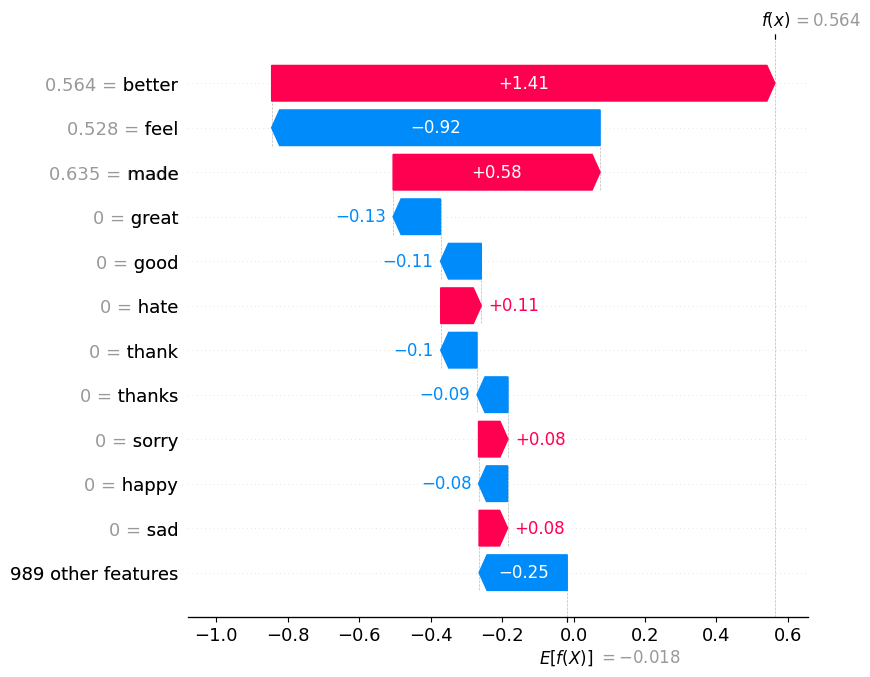

In [ ]:
# Gráfico local tipo waterfall para o comentário selecionado
# Este gráfico mostra como cada palavra aproxima ou afasta a previsão da classe positive.
def get_base_value_for_row(shap_explanation, row_index=0, class_index=0):
    base_values = shap_explanation.base_values

    if isinstance(base_values, list):
        return base_values[class_index]

    base_values = np.asarray(base_values)

    if base_values.ndim == 0:
        return float(base_values)
    if base_values.ndim == 1:
        return float(base_values[row_index])
    if base_values.ndim == 2:
        return float(base_values[row_index, class_index])

    return float(np.ravel(base_values)[0])

base_value_local = get_base_value_for_row(
    shap_values_local,
    row_index=0,
    class_index=positive_class_index
)

waterfall_explanation = shap.Explanation(
    values=local_values,
    base_values=base_value_local,
    data=matriz_comentario.toarray().reshape(-1),
    feature_names=feature_names
)

shap.plots.waterfall(waterfall_explanation, max_display=12)


## 14.6 Explicação textual automática

Para tornar a interpretação mais acessível, a célula seguinte transforma os principais valores SHAP numa explicação textual. Esta abordagem permite comunicar os resultados da previsão de forma simples, mesmo para utilizadores sem conhecimentos técnicos avançados.


In [ ]:
print("EXPLICAÇÃO AUTOMÁTICA:\n")

# Nota: a interpretação é sempre feita em relação à classe 'positive'.
# Um impacto SHAP positivo empurra a previsão para 'positive';
# um impacto negativo empurra-a no sentido contrário (para 'negative').
for _, row in local_explanation_df.head(10).iterrows():
    palavra = row['palavra']
    impacto = row['impacto_shap']
    direcao = "POSITIVA" if impacto >= 0 else "NEGATIVA"

    print(
        f"A palavra '{palavra}' teve influência {direcao} "
        f"na previsão da classe 'positive' "
        f"(impacto SHAP = {impacto:.4f})."
    )

EXPLICAÇÃO AUTOMÁTICA:

A palavra 'better' teve influência POSITIVA na previsão da classe 'positive' (impacto SHAP = 1.4085).
A palavra 'feel' teve influência NEGATIVA na previsão da classe 'positive' (impacto SHAP = -0.9193).
A palavra 'made' teve influência POSITIVA na previsão da classe 'positive' (impacto SHAP = 0.5793).


## 14.7 Síntese da análise Explainable AI

A aplicação de Explainable AI permitiu complementar a avaliação quantitativa dos modelos com uma análise interpretável das suas decisões. Enquanto as métricas de desempenho indicam **quanto** o modelo acerta, o SHAP ajuda a compreender **porque** determinada previsão foi feita.

A análise global permitiu identificar as palavras/features mais influentes no comportamento geral do classificador. A análise local, por sua vez, mostrou como palavras específicas de um comentário contribuíram positiva ou negativamente para a previsão.

Esta secção reforça a transparência do projeto, permitindo validar se o modelo está a apoiar as suas decisões em padrões linguísticos coerentes com a análise de sentimentos no domínio da saúde mental.


## 14.8 Limitações do Estudo

Apesar de o projeto apresentar um pipeline completo de Text Mining, existem algumas limitações que devem ser consideradas na interpretação dos resultados.

Em primeiro lugar, a remoção da classe `neutral` simplificou o problema para uma classificação binária entre sentimentos positivos e negativos. Esta decisão tornou a modelação mais clara e reduziu a ambiguidade, mas também retirou uma parte da complexidade original do dataset.

Em segundo lugar, a aplicação de **oversampling** ajudou a equilibrar as classes, mas pode introduzir repetição de padrões existentes nos dados de treino. No entanto, nesta versão corrigida, o oversampling foi aplicado **apenas ao conjunto de treino**, mantendo o conjunto de teste intacto e reduzindo o risco de *data leakage*.

Outra limitação está relacionada com o custo computacional dos modelos baseados em Transformers. Embora o **DistilBERT** tenha obtido o melhor desempenho global, exige mais recursos e tempo de treino do que os modelos clássicos, o que pode limitar a sua aplicação em contextos com menos capacidade computacional.

Por fim, a análise de **Explainable AI** foi aplicada a um modelo clássico com representação TF-IDF, por permitir uma associação mais direta entre palavras e impacto na previsão. Esta opção favorece a interpretabilidade, embora não explique diretamente o funcionamento interno do DistilBERT.

# 15. Análises Adicionais: Significância Estatística e Robustez

Para além do pipeline principal, foram acrescentadas duas análises complementares que vão além das técnicas habituais de avaliação. A primeira verifica, com um teste estatístico, se a superioridade do DistilBERT face ao melhor modelo clássico é estatisticamente significativa ou se pode resultar do acaso. A segunda avalia a **robustez** do modelo, analisando se o seu desempenho se mantém estável entre diferentes subgrupos de utilizadores (idade, país e período do dia), uma preocupação de *fairness* cada vez mais relevante em aplicações reais.


## 15.1 Significância Estatística da Diferença entre Modelos (Teste de McNemar)

Afirmar que o DistilBERT supera a Logistic Regression apenas com base na diferença numérica das métricas pode ser enganador, sobretudo em conjuntos de teste pequenos. O **teste de McNemar** é indicado para comparar dois classificadores avaliados **exatamente no mesmo conjunto de exemplos**, pois analisa apenas os casos em que os modelos discordam: quando um acerta e o outro erra.

Para garantir uma comparação emparelhada e justa, ambos os modelos são avaliados sobre o mesmo conjunto de teste do DistilBERT (`test_llm`): o DistilBERT recebe o texto original e a Logistic Regression recebe o texto pré-processado correspondente a esses mesmos comentários.

A interpretação segue diretamente o *p-value* impresso pela célula seguinte: se **p < 0.05**, a diferença de desempenho entre os dois modelos é estatisticamente significativa; se **p ≥ 0.05**, não existe evidência estatística suficiente para afirmar que um modelo é superior ao outro — o que, em conjuntos de teste reduzidos, é um resultado possível e que deve ser reportado com honestidade.

In [ ]:
# Teste de McNemar: a diferença DistilBERT vs Logistic Regression e estatisticamente significativa?
try:
    from statsmodels.stats.contingency_tables import mcnemar
except ImportError:
    !pip -q install statsmodels
    from statsmodels.stats.contingency_tables import mcnemar

# 1) Verdade no conjunto comum (em rotulos de texto)
y_true_common = [id2label[int(l)] for l in test_llm['label'].values]

# 2) Previsoes do DistilBERT (texto original) nos mesmos exemplos
bert_pred_common, _ = predict_with_distilbert(test_llm[TEXT_COL].tolist(), trainer, tokenizer, id2label)

# 3) Previsoes do Multinomial NB nos MESMOS exemplos (texto pre-processado correspondente)
texto_pp_common = llm_sample.loc[test_llm.index, 'text_preprocessed'].fillna('').astype(str)
nb_pred_common = best_model.predict(vectorizer_model.transform(texto_pp_common))

# 4) Acertos de cada modelo
acertou_bert = np.array(bert_pred_common) == np.array(y_true_common)
acertou_nb   = np.array(list(nb_pred_common)) == np.array(y_true_common)

# 5) Tabela de contingencia 2x2 para o teste de McNemar
both_correct = int(np.sum(acertou_bert & acertou_nb))
bert_only    = int(np.sum(acertou_bert & ~acertou_nb))
nb_only      = int(np.sum(~acertou_bert & acertou_nb))
both_wrong   = int(np.sum(~acertou_bert & ~acertou_nb))
tabela = [[both_correct, nb_only], [bert_only, both_wrong]]

print(f'Exemplos avaliados (conjunto comum): {len(y_true_common)}')
print(f'Accuracy DistilBERT: {acertou_bert.mean():.4f} | Accuracy {best_model_name}: {acertou_nb.mean():.4f}')
print(f'Ambos certos: {both_correct} | So DistilBERT certo: {bert_only} | So {best_model_name} certo: {nb_only} | Ambos errados: {both_wrong}')

# Teste exato (binomial) quando as celulas discordantes tem poucas observacoes
usar_exato = (bert_only + nb_only) < 25
resultado = mcnemar(tabela, exact=usar_exato, correction=True)
print(f'\nEstatistica McNemar: {resultado.statistic:.4f}')
print(f'p-value: {resultado.pvalue:.4f}')
alpha = 0.05
if resultado.pvalue < alpha:
    print(f'Como p < {alpha}, a diferenca de desempenho entre os modelos e estatisticamente significativa.')
else:
    print(f'Como p >= {alpha}, nao ha evidencia estatistica de diferenca significativa (possivel devido ao tamanho reduzido do conjunto de teste).')


Exemplos avaliados (conjunto comum): 320
Accuracy DistilBERT: 0.9000 | Accuracy Logistic Regression: 0.8875
Ambos certos: 265 | So DistilBERT certo: 23 | So Logistic Regression certo: 19 | Ambos errados: 13

Estatistica McNemar: 0.2143
p-value: 0.6434
Como p >= 0.05, nao ha evidencia estatistica de diferenca significativa (possivel devido ao tamanho reduzido do conjunto de teste).


### Interpretação do Teste de McNemar

No conjunto comum de **320 exemplos**, o DistilBERT obteve **accuracy de 0.9000**, enquanto a Logistic Regression obteve **accuracy de 0.8875**. O DistilBERT acertou sozinho em **23 casos**, a Logistic Regression acertou sozinha em **19 casos**, ambos acertaram em **265 casos** e ambos erraram em **13 casos**.

Apesar da vantagem numérica do DistilBERT, o teste de McNemar apresentou **p-value de 0.6434**, superior ao limiar de 0.05. Assim, não existe evidência estatística suficiente para afirmar que a diferença entre os dois modelos é significativa neste subconjunto de teste.

Este resultado não invalida a superioridade global do DistilBERT nas métricas principais, mas recomenda uma interpretação prudente: o modelo Transformer apresentou melhor desempenho, embora a diferença observada não tenha sido estatisticamente significativa nesta amostra reduzida.

## 15.2 Análise de Robustez por Subgrupos (Idade, País e Período do Dia)

Uma accuracy global elevada pode esconder desempenhos muito diferentes entre subgrupos de utilizadores. Esta análise verifica se o modelo é **robusto e equitativo**, medindo a accuracy separadamente por faixa etária, país e período do dia: variáveis que tinham sido exploradas na análise exploratória mas que não eram usadas na modelação.

Para evitar a contaminação introduzida pelo *oversampling* (que cria cópias sintéticas sem informação demográfica), a avaliação é feita num conjunto de teste construído a partir dos dados **reais**, com uma divisão dedicada que preserva as colunas demográficas. O *oversampling* é aplicado apenas ao treino, mantendo o conjunto de teste isento de duplicações. Os valores absolutos podem, por isso, diferir ligeiramente do modelo principal; o que importa nesta análise são as **diferenças relativas** entre subgrupos face à accuracy global (linha vermelha nos gráficos).


Accuracy global no conjunto de teste de robustez: 0.8318
Tamanho do conjunto de teste: 4850

--- Accuracy por 'Age of User' (subgrupos com >= 30 exemplos) ---
               mean  count
Age of User               
60-70        0.8203    818
46-60        0.8224    805
21-30        0.8241    813
0-20         0.8396    798
70-100       0.8420    823
31-45        0.8424    793 



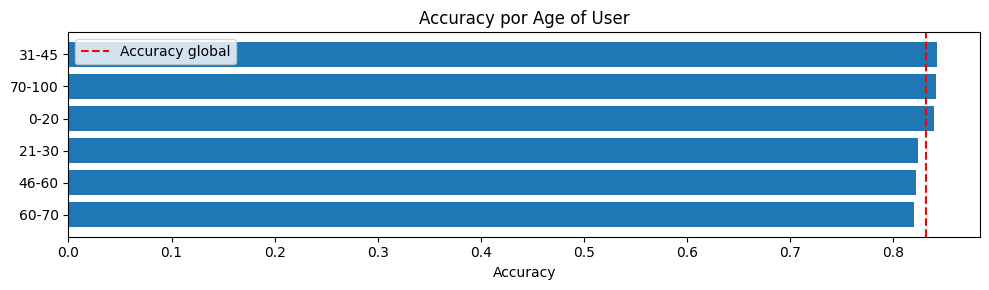

--- Accuracy por 'Country' (subgrupos com >= 30 exemplos) ---
                            mean  count
Country                                
Germany                   0.7353     34
Angola                    0.7561     41
Cabo Verde                0.7812     32
Egypt                     0.8125     32
Barbados                  0.8125     32
Myanmar (formerly Burma)  0.8286     35
Guinea-Bissau             0.8293     41
Netherlands               0.8333     36
Azerbaijan                0.8421     38
Czechia (Czech Republic)  0.8571     35
Mongolia                  0.8649     37
Gabon                     0.8750     32
Yemen                     0.8788     33
El Salvador               0.8919     37
Chad                      0.9355     31 



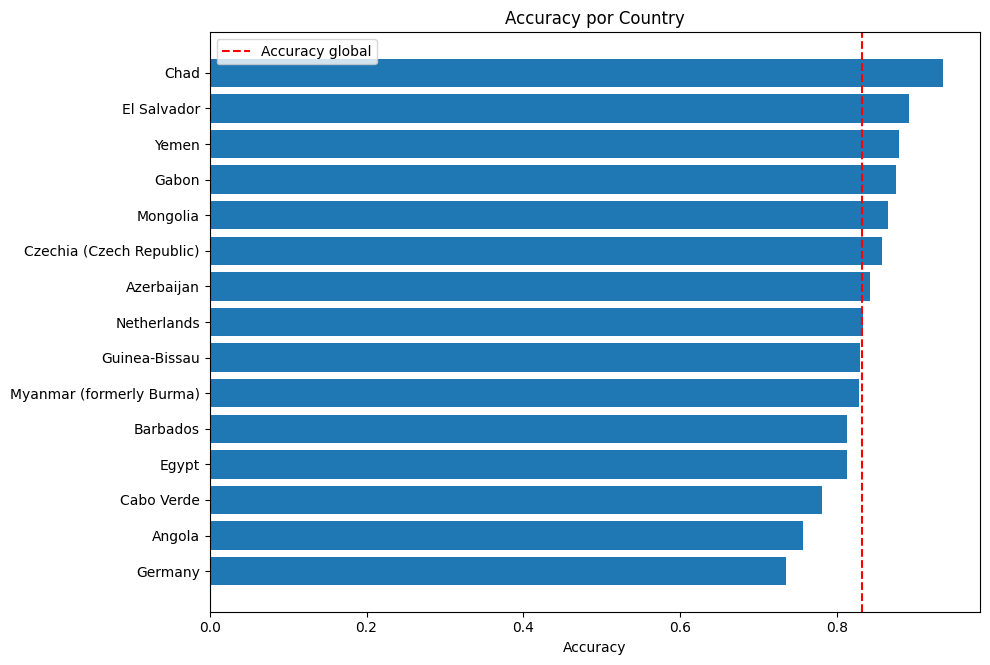

--- Accuracy por 'Time of Tweet' (subgrupos com >= 30 exemplos) ---
                 mean  count
Time of Tweet               
noon           0.8222   1631
morning        0.8309   1603
night          0.8422   1616 



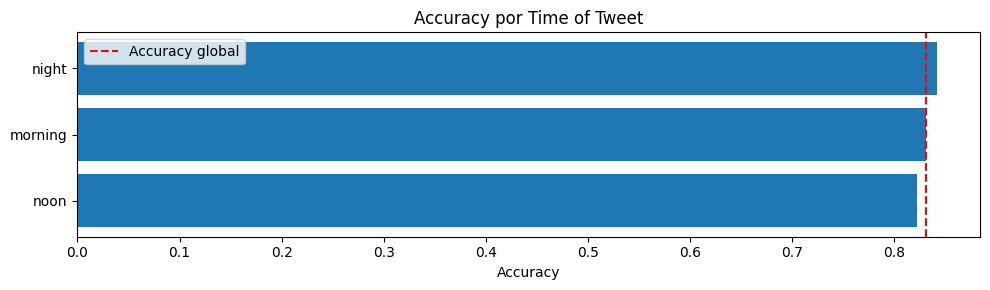

In [ ]:
# Analise de robustez/justica: o desempenho varia entre subgrupos?
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt

cols_demograficas = ['Age of User', 'Country', 'Time of Tweet']
cols_existentes = [c for c in cols_demograficas if c in review_df.columns]

fair_df = review_df[['text_preprocessed', TARGET_COL] + cols_existentes].copy()
fair_df['text_preprocessed'] = fair_df['text_preprocessed'].fillna('').astype(str)
fair_df = fair_df[fair_df['text_preprocessed'].str.strip() != '']

# Divisao dedicada que preserva as colunas demograficas
fair_train, fair_test = train_test_split(
    fair_df, test_size=0.30, random_state=0, stratify=fair_df[TARGET_COL]
)

# Oversampling apenas no treino (o teste mantem-se com dados reais)
ros_fair = RandomOverSampler(random_state=42)
X_tr_text, y_tr = ros_fair.fit_resample(fair_train[['text_preprocessed']], fair_train[TARGET_COL])

vec_fair = TfidfVectorizer(max_features=1000)
X_tr = vec_fair.fit_transform(X_tr_text['text_preprocessed'])
X_te = vec_fair.transform(fair_test['text_preprocessed'])

modelo_fair = MultinomialNB()
modelo_fair.fit(X_tr, y_tr)

fair_test = fair_test.copy()
fair_test['pred'] = modelo_fair.predict(X_te)
fair_test['acertou'] = (fair_test['pred'] == fair_test[TARGET_COL]).astype(int)

acc_global = fair_test['acertou'].mean()
print(f'Accuracy global no conjunto de teste de robustez: {acc_global:.4f}')
print(f'Tamanho do conjunto de teste: {len(fair_test)}\n')

for col in cols_existentes:
    grupo = fair_test.groupby(col)['acertou'].agg(['mean', 'count'])
    grupo = grupo[grupo['count'] >= 30]
    if col == 'Country':
        grupo = grupo.sort_values('count', ascending=False).head(15)
    grupo = grupo.sort_values('mean')
    if len(grupo) == 0:
        continue
    print(f"--- Accuracy por '{col}' (subgrupos com >= 30 exemplos) ---")
    print(grupo.round(4), '\n')
    plt.figure(figsize=(10, max(3, 0.45 * len(grupo))))
    plt.barh(grupo.index.astype(str), grupo['mean'])
    plt.axvline(acc_global, color='red', linestyle='--', label='Accuracy global')
    plt.xlabel('Accuracy'); plt.title(f'Accuracy por {col}'); plt.legend(); plt.tight_layout()
    plt.show()


### Interpretação da Análise de Robustez

A análise de robustez apresentou uma **accuracy global de 0.8318** no conjunto de teste dedicado a esta avaliação. Por faixa etária, os resultados foram relativamente estáveis, variando entre **0.8203** e **0.8424**, o que sugere que o modelo clássico mantém desempenho semelhante entre grupos etários.

Por período do dia, a performance também se manteve próxima da média global: **0.8222** em `noon`, **0.8309** em `morning` e **0.8422** em `night`. Estas diferenças são moderadas e não sugerem uma instabilidade forte do modelo nestes subgrupos.

A análise por país apresentou maior variação, com accuracies entre **0.7353** e **0.9355** nos países com pelo menos 30 exemplos. No entanto, estes resultados devem ser interpretados com cautela, porque cada país tem um número reduzido de observações no teste. Assim, pequenas alterações no número de acertos podem produzir diferenças percentuais relativamente grandes.

De forma geral, a análise sugere que o modelo é relativamente estável por idade e período do dia, mas que a avaliação por país exigiria uma amostra maior para conclusões mais robustas.

# 16. Conclusões

O presente trabalho demonstrou a aplicação de técnicas de Text Mining à análise de sentimentos, combinando abordagens clássicas de Machine Learning com um modelo de linguagem pré-treinado.

A metodologia seguida permitiu transformar texto não estruturado numa representação adequada à modelação, através de um pipeline composto por limpeza textual, normalização, remoção de ruído, lematização, vetorização TF-IDF, seleção de atributos, balanceamento com oversampling e treino de classificadores supervisionados. Nesta versão corrigida, a divisão treino/teste foi realizada antes da vetorização, da seleção de atributos e do oversampling, garantindo uma avaliação mais rigorosa e reduzindo o risco de *data leakage*.

Na fase de classificação, foram comparados diferentes modelos tradicionais, incluindo abordagens lineares, probabilísticas, baseadas em árvores e ensemble learning. O melhor desempenho clássico foi obtido pela **Logistic Regression**, com **accuracy de 0.8352**, **precision de 0.8655**, **recall de 0.8120**, **F1-score de 0.8379** e **Kappa de 0.6707**, evidenciando a adequação de modelos lineares a representações TF-IDF.

A experiência com **DistilBERT fine-tuned** apresentou o melhor desempenho global, alcançando **accuracy de 0.9000**, **precision de 0.9638**, **recall de 0.8313**, **F1-score de 0.8926** e **Kappa de 0.8000** na versão com texto original. Estes resultados confirmam a vantagem dos modelos baseados em Transformers na captura de relações semânticas mais complexas.

A comparação entre DistilBERT com e sem pré-processamento mostrou que o texto original produziu melhores resultados do que o texto pré-processado. Este resultado é metodologicamente relevante, pois demonstra que o pré-processamento, embora fundamental para modelos tradicionais baseados em TF-IDF, pode remover informação contextual útil para modelos de linguagem.

Importa referir que os resultados do fine-tuning podem apresentar pequenas variações entre execuções. Estas variações são normais em modelos de deep learning, devido a fatores como aleatoriedade no processo de treino, ordem dos batches, inicialização de pesos e diferenças do ambiente de execução. Para mitigar esse problema, foram fixadas seeds no processo de treino, tornando os resultados mais reprodutíveis. Ainda assim, a tendência principal manteve-se consistente: o DistilBERT foi o melhor modelo global e a versão com texto original superou a versão com texto pré-processado.

A análise de erros mostrou que ainda existem dificuldades na classificação de textos ambíguos ou emocionalmente subtis, sobretudo quando a polaridade depende fortemente do contexto. No conjunto de teste analisado, foram identificados **32 erros**, correspondentes a uma taxa de erro aproximada de **10.00%**. Este resultado reforça a importância de complementar métricas quantitativas com análise qualitativa dos erros.

A secção de **Explainable AI com SHAP** acrescentou interpretabilidade ao projeto, permitindo identificar quais as palavras/features que mais influenciam as decisões do modelo clássico. Esta análise reforça a transparência do processo de classificação e permite compreender melhor os fatores linguísticos associados a sentimentos positivos e negativos.

As análises adicionais reforçaram a maturidade metodológica do projeto. O teste de McNemar indicou que, apesar da vantagem numérica do DistilBERT face à Logistic Regression, a diferença não foi estatisticamente significativa no subconjunto comum analisado (**p-value = 0.6434**). A análise de robustez mostrou ainda que o desempenho do modelo clássico foi relativamente estável por faixa etária e período do dia, embora a análise por país deva ser interpretada com cautela devido ao menor número de exemplos por subgrupo.

Como limitações principais, destacam-se a remoção da classe `neutral`, que simplificou o problema mas reduziu a complexidade original da tarefa, a possibilidade de repetição de padrões no treino devido ao oversampling e o maior custo computacional dos modelos Transformer. Ainda assim, o pipeline corrigido aplica o oversampling apenas ao treino, preservando o conjunto de teste como avaliação independente.

De forma geral, os resultados obtidos demonstram que a combinação entre pré-processamento cuidadoso, comparação estruturada de algoritmos, validação de modelos, análise de erros, LLMs, significância estatística, robustez por subgrupos e Explainable AI permite construir uma solução sólida, interpretável e metodologicamente mais rigorosa para análise de sentimentos em dados textuais.

# 17. Referências

- Aizawa, A., et al. (2023). Sentiments about Mental Health on Twitter — Before and during the COVID-19 Pandemic. *Healthcare*, 11(21), 2893. https://doi.org/10.3390/healthcare11212893
- Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding. *NAACL-HLT*.
- Dietterich, T. G. (1998). Approximate Statistical Tests for Comparing Supervised Classification Learning Algorithms. *Neural Computation*, 10(7), 1895–1923.
- IEEE (2024). Understanding Mental Health through Sentiment Analysis using Machine Learning to Analyze Social Media for Emotional Insights. *IEEE Conference Publication*. https://doi.org/10.1109/10810855
- Liu, B. (2012). *Sentiment Analysis and Opinion Mining*. Morgan & Claypool Publishers.
- Lundberg, S. M., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *Advances in Neural Information Processing Systems*, 30.
- Lossio-Ventura, J. A., et al. (2024). A Comparison of ChatGPT and Fine-Tuned OPT Against Widely Used Sentiment Analysis Tools: Sentiment Analysis of COVID-19 Survey Data. *JMIR Mental Health*, 11, e50150. https://doi.org/10.2196/50150
- McNemar, Q. (1947). Note on the sampling error of the difference between correlated proportions or percentages. *Psychometrika*, 12(2), 153–157.
- Obagbuwa, I. C., Danster, S., & Chibaya, O. C. (2023). Supervised machine learning models for depression sentiment analysis. *Frontiers in Artificial Intelligence*, 6, 1230649. https://doi.org/10.3389/frai.2023.1230649
- Pang, B., Lee, L., & Vaithyanathan, S. (2002). Thumbs up? Sentiment classification using machine learning techniques. *Proceedings of EMNLP*.
- Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*.
- Sanh, V., Debut, L., Chaumond, J., & Wolf, T. (2019). DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter. *arXiv preprint arXiv:1910.01108*.
- Sankar, H., et al. (2024). Sentiment Analysis on Twitter Data for Depression Detection. *Journal of Logistics, Informatics and Service Science*, 11(3), 21–36.
- Vaswani, A., Shazeer, N., Parmar, N., et al. (2017). Attention Is All You Need. *NeurIPS*.